# Машинное обучение, ФКН ВШЭ

# Практическое задание 6. Бустинговое

## Общая информация

Дата выдачи: 11.05.2026

Мягкий дедлайн: 25.05.2026 23:59 MSK

Жёсткий дедлайн: 31.05.2026 23:59 MSK

## Оценивание и штрафы

Каждая из задач имеет определенную «стоимость» (указана в скобках около задачи). Максимально допустимая оценка за работу — 10 баллов.

Задание выполняется самостоятельно. «Похожие» решения считаются плагиатом и все задействованные студенты (в том числе те, у кого списали) не могут получить за него больше 0 баллов (подробнее о плагиате см. на странице курса). Если вы нашли решение какого-то из заданий (или его часть) в открытом источнике, необходимо указать ссылку на этот источник в отдельном блоке в конце вашей работы (скорее всего вы будете не единственным, кто это нашел, поэтому чтобы исключить подозрение в плагиате, необходима ссылка на источник).

Неэффективная реализация кода может негативно отразиться на оценке.

## Формат сдачи
Задания сдаются через систему anytask. Посылка должна содержать:
* Ноутбук homework-practice-06-Username.ipynb
* Модуль boosting.py

Username — ваша фамилия на латинице

## О задании

В этом задании вам предстоит вручную запрограммировать один из самых мощных алгоритмов машинного обучения — бустинг. Однако с большой силой приходит и большая ответственность, поэтому придется научиться им пользоваться

### Как воспроизвести решение

Работа выполнена на приложенном `hw6_dataset.pq`. Основная реализация находится в
`boosting.py`; готовые ансамбли используются только там, где разрешены заданием.
Разбиение: train — годы < 2011, valid — 2011, test — 2013. Все сравнения и подбор
гиперпараметров проводятся по valid. Test используется в исходной проверке задания 1
и для итоговых метрик/калибровочных графиков после подбора. Пропуски в исходном датасете
отсутствуют, но их обработка предусмотрена. Сид всех случайных процедур — 69.

Зависимости перечислены в `requirements.txt`. Запускать все ячейки по порядку из `ДЗ_3`.
Музыкальный бонус пропущен по указанию пользователя.


In [1]:
from pathlib import Path
from time import perf_counter
import json
import platform
import importlib.metadata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from sklearn.metrics import roc_auc_score, log_loss, brier_score_loss
from sklearn.model_selection import train_test_split

SEED = 69
np.random.seed(SEED)
sns.set_theme(style="darkgrid", palette="colorblind")
plt.rcParams.update({"figure.figsize": (9, 4), "figure.dpi": 110})
DATA_DIR = Path.cwd() if (Path.cwd() / "hw6_dataset.pq").exists() else Path.cwd() / "ДЗ_3"
results = []
models = {}

def compare_curves(named_models, metric="roc_auc"):
    fig, axes = plt.subplots(1, 2, figsize=(13, 4))
    for name, model in named_models.items():
        for ax, split in zip(axes, ["train", "valid"]):
            values = model.history[f"{split}_{metric}"]
            ax.plot(np.arange(1, len(values) + 1), values, label=name)
            ax.set(title=split, xlabel="Итерация", ylabel=metric)
    axes[-1].legend(fontsize=8)
    fig.tight_layout()
    plt.show()

def register(name, model, valid_X, elapsed):
    # Для ordered encoding train оценивается по представлению, на котором обучались деревья.
    idx = model.best_iteration_ if model.n_estimators_ != len(model.history["train_loss"]) else -1
    results.append({"model": name, "iterations": model.n_estimators_, "seconds": elapsed,
                    "train_auc": float(model.history["train_roc_auc"][idx]),
                    "valid_auc": model.score(valid_X, y_valid),
                    "valid_logloss": log_loss(y_valid > 0, model.predict_proba(valid_X)[:, 1])})
    models[name] = model
    display(pd.DataFrame(results).tail(1).round(5))

print("Python", platform.python_version())
versions = {p: importlib.metadata.version(p) for p in
            ["numpy", "pandas", "scipy", "scikit-learn", "matplotlib", "seaborn",
             "pyarrow", "optuna", "xgboost", "lightgbm", "catboost", "nbclient", "ipykernel"]}
display(pd.Series(versions, name="version"))


Python 3.14.8


numpy            2.4.6
pandas           3.1.0
scipy           1.18.1
scikit-learn     1.9.1
matplotlib      3.11.2
seaborn         0.13.2
pyarrow         25.0.1
optuna           5.0.0
xgboost          3.4.1
lightgbm         4.7.0
catboost        1.2.10
nbclient        0.11.0
ipykernel        7.3.0
Name: version, dtype: str

Мы будем работать с датасетом по предсказанию гендера. Никакие фичи мы придумывать не будем, но если вам интересно, в датасете имеется:

- region — регион, в котором проводили опрос
- age — возраст опрошенного
- year — год опроса
- race — этническая принадлежность
- sch — количество классов образования
- empstat — статус трудоустройства
- occ — код профессии
- ind — код индустрии, в которой человек работает
- annhrs — число часов работы в год
- hrwage — почасовая оплата
- incwage — суммарная оплата в год
- occupation — должность

Целевая метрика ROC-AUC, потому что мы непритязательны и это не фокус этой домашки



In [2]:
df = pd.read_parquet(DATA_DIR / "hw6_dataset.pq")
X = df.drop("sex", axis=1)
y = df["sex"]
assert set(y.unique()) == {-1, 1}
assert not df.isna().any().any()
display(df.head())
display(df.groupby("year")["sex"].agg(["size", "mean"]))
display(y.value_counts(normalize=True).rename("class_fraction"))


,region,age,year,sex,race,sch,empstat,occ,annhrs,hrwage,incwage,occupation
0,12,58,1990,1,3,12.0,10,335,8.0,8.0,8.0,officeadmin
1,33,28,2009,1,1,12.0,10,5120,8.0,8.0,8.0,officeadmin
2,12,37,1990,1,1,14.0,10,217,13.0,13.0,13.0,architect
3,42,34,1990,1,1,18.0,10,64,13.0,13.0,13.0,computer
4,31,38,1981,1,4,13.0,10,245,8.0,8.0,8.0,manager


,size,mean
year,,
1981,42379,0.110314
1990,45033,0.031643
1999,37144,0.016046
2007,56467,0.009793
2009,55617,-0.007821
2011,53857,0.001133
2013,53790,0.012270


sex
 1    0.510943
-1    0.489057
Name: class_fraction, dtype: float64

**Особенности данных.** В файле 344 287 строк, train/valid/test содержат 236 640/53 857/53 790 объектов. Доли классов примерно 51.1% и 48.9%, пропусков нет. В предоставленном файле `annhrs`, `hrwage` и `incwage` полностью совпадают; они сохранены согласно исходному заданию, но их отдельные важности нельзя интерпретировать независимо.

Пока что мы временно выкинем колонку с должностью, но мы к ней обязательно вернемся

Разделим на обучающую, валидационную и тестовую выборки по годам, чтобы предсказывать будущее, а не прошлое

In [3]:
train_mask, valid_mask, test_mask = X.year < 2011, X.year == 2011, X.year == 2013
numeric_columns = X.columns.drop("occupation").tolist()
X_train_numeric = X.loc[train_mask, numeric_columns].to_numpy()
X_valid_numeric = X.loc[valid_mask, numeric_columns].to_numpy()
X_test_numeric = X.loc[test_mask, numeric_columns].to_numpy()
y_train, y_valid, y_test = (y.loc[m].to_numpy() for m in [train_mask, valid_mask, test_mask])
# В файле строки сгруппированы по sex. Перестановка не использует значения y.
train_permutation = np.random.default_rng(SEED).permutation(len(y_train))
X_train_numeric = X_train_numeric[train_permutation]
y_train = y_train[train_permutation]
X_train, X_valid, X_test = X_train_numeric, X_valid_numeric, X_test_numeric
print("train / valid / test:", X_train.shape, X_valid.shape, X_test.shape)


train / valid / test: (236640, 10) (53857, 10) (53790, 10)


Домашнее задание имеет нелинейную структуру. В нём есть <font color='lightcoral'>📌 **обязательные**</font> части, без которых будет тяжко <font color='lightcoral'>**(6 баллов)**</font>, и целая куча 💠 **опциональных**, которыми можно добить оценку до 10, делайте то, что нравится больше! **Музыкальный бонус** идёт отдельно, за него можно получить ещё 0.5 балла.

---

## 📌 Задание 1. Базовый градиентный бустинг (4 балла)

Это задание <font color='lightcoral'>**📌 обязательное**</font>, без него домашка не имеет смысла! Ещё раз обращаем внимание, что **опциональные** задания помечены 💠

Первая часть посвящена реализации собственного градиентного бустинга. Обращаем внимание, что пользоваться готовыми реализациями <font color='lightcoral'>**нельзя**</font>, если специально не оговорено. На все <font color='lightcoral'>**вопросы**</font> должен быть <font color='lightcoral'>**ответ**</font>. В заданиях, где нужно делать параметры, часто есть референсы из других библиотек. На случай, если объяснение из ноутбука непонятно, советуем обратиться к соответствующей документации и пощупать, как это делается там

Вам нужно дописать код в файлике `boosting.py`. Для вас уже подготовлен шаблон класса `Boosting`, вы можете менять его по своему усмотрению.

### Инструкции для функций:

#### `__init__`

Существующие параметры:
- `base_model_class` — класс базовой модели нашего бустинга
- `base_model_params` — словарь с гиперпараметрами для базовой модели
- `n_estimators` — какое количество базовых моделей нужно обучить
- `learning_rate` — темп обучения, должен быть из полуинтервала $(0, 1]$
- `random_state`— в роли рандом стейта
- `verbose` — для тех, кому не нравится загадочность, можно включить и увидеть, сколько еще ждать конца обучения

#### `fit`

В `fit` приходит выборка, на которой мы обучаем новые базовые модели

1. Сначала нам нужно сделать какую-то нулевую модель, сделать предсказания (в шаблоне это нулевая модель, соответственно предсказания это просто `np.zeros`).
2. После этого нужно обучить `n_estimators` базовых моделей (как и на что обучаются базовые модели смотрите в лекциях и семинарах).
3. После каждой обученной базовой модели мы должны обновить текущие предсказания, посчитать ошибку на выборке (используем `loss_fn` для этого) и найти новую оптимальную гамму

#### `partial_fit`

В `partial_fit` передаются данные `X: np.ndarray, y: np.ndarray` для одного шага бустинга: обучаем следующую базовую модель на антиградиенте и обновляем ансамбль.

#### `predict_proba`

В `predict_proba` приходит любая выборка, нужно предсказать вероятности для неё. Суммируем предсказания базовых моделей на этой выборке (не забываем про гаммы) и накидываем сигмоиду

In [4]:
%load_ext autoreload


In [5]:
%autoreload 2
from boosting import Boosting, TargetEncoder, Quantizer, NewtonTreeRegressor, find_best_split


/home/skylak3/.local/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


### Проверка кода

Train ROC-AUC 0.8013


Valid ROC-AUC 0.7247


Test ROC-AUC 0.7196


,model,iterations,seconds,train_auc,valid_auc,valid_logloss
0,numeric_baseline,50,27.80987,0.80128,0.72466,0.62447


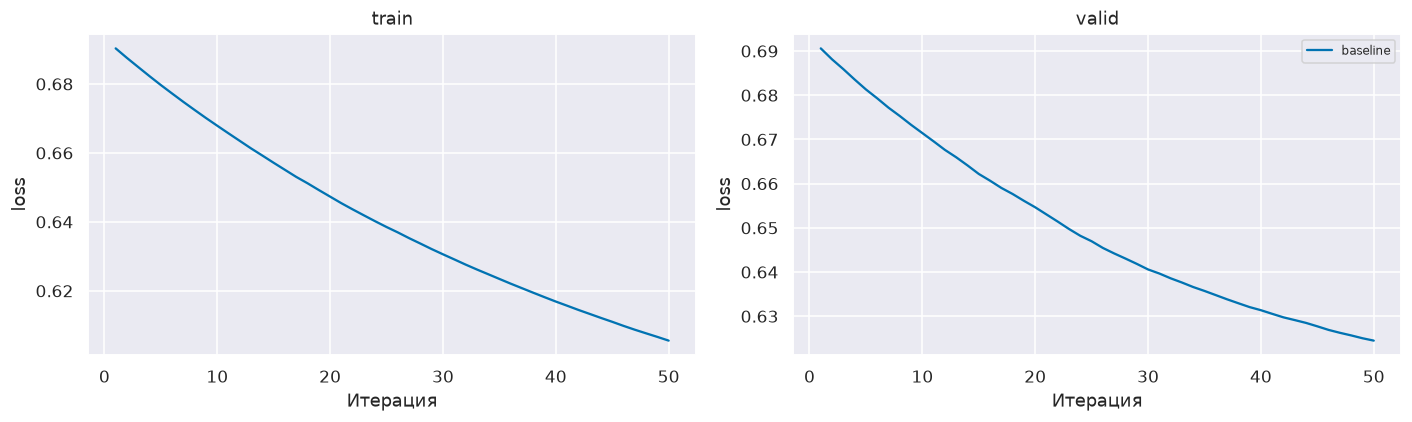

In [6]:
boosting = Boosting(verbose=False, base_model_params=dict(max_depth=5),
                    n_estimators=50, random_state=SEED)
start = perf_counter()
boosting.fit(X_train, y_train, eval_set=(X_valid, y_valid))
baseline_seconds = perf_counter() - start
assert len(boosting.models) == boosting.n_estimators
assert len(boosting.gammas) == boosting.n_estimators
assert boosting.predict_proba(X_test).shape == (X_test.shape[0], 2)
assert np.all(np.diff(boosting.history["train_loss"]) <= 1e-12)
assert np.allclose(boosting.predict_proba(X_test).sum(axis=1), 1)
for name, xx, yy in [("Train", X_train, y_train), ("Valid", X_valid, y_valid), ("Test", X_test, y_test)]:
    print(f"{name} ROC-AUC {boosting.score(xx, yy):.4f}")
register("numeric_baseline", boosting, X_valid, baseline_seconds)
compare_curves({"baseline": boosting}, "loss")


Для $y\in\{-1,+1\}$ используются $L(y,z)=\log(1+e^{-yz})$,
$\partial L/\partial z=-y\sigma(-yz)$ и $\partial^2L/\partial z^2=\sigma(yz)\sigma(-yz)$.
Вычисления через `logaddexp` и `expit` устойчивы при больших отступах.
Гамма минимизирует loss на отрезке [0, 1]; для BCE решается уравнение производной,
а при минимуме на границе выбирается граница. Нулевая гамма допустима и исключает
ухудшение train loss при обычном градиентном шаге.


**Наблюдение.** Базовая числовая модель даёт train AUC 0.8013 и valid AUC 0.7247. Разрыв показывает, что обобщение на будущий год заметно хуже подгонки train.


---

## Задание 2. Имплементация гиперпараметров (📌 1 балл |💠 8.25 балла)

Бустинг, как метод агрегации, предлагает несколько вариантов регуляризации.

В этом пункте мы будем делать кучу самых разных гиперпараметров, каждый из них прекрасен по-своему, но полноценно их эффект получится ощутить лишь на этапе их перебора (кроме, пожалуй, `rsm`), поэтому делать третью часть до второй не рекомендуется

<font color='lightcoral'>**Важно!**</font> После добавления каждого параметра проверьте, как это повлияет на качество. Специально крутить параметры не нужно, но важно увидеть, что перформанс модели изменился, в худшую или в лучшую сторону. Для этого какие-то параметры нужны, пусть и от балды, <font color='lightcoral'>**гарантии, что дефолтные параметры подойдут, нет**</font>. Лучше всего это видно по графикам обучения <font color='lightcoral'>**на трейне и валидации**</font>, рекомендуется смотреть именно на них

### 📌 2.1. Борьба с переобучением (0.5 балла)

Как известно, бустинги бывают склонны к переобучению. Чтобы этого не допустить, можно контролировать процесс обучения и проверять критерий останова на валидации прямо во время обучения. Реализуйте такую процедуру, не забудьте, что всю предобработку, что вы будете в дальнейшем делать для трейна, нужно будет повторить на валидации

Добавьте в вашу модель:
- `early_stopping_rounds: int | None = 0` — число раундов для критерия останова. Если качество ухудшается на протяжении всех раундов подряд, останавливаем обучение
- `eval_metric: str | None = None` — метрика, на которую смотрим, чтобы остановить обучение, может быть ключом из `model.history`
- `plot_history(self, keys: str | Iterable[str])` — метод, который строит график изменения метрики по ключам из `model.history`

И конкретно в метод `model.fit`:
- `eval_set: tuple[np.ndarray] | None = None` — валидационная выборка `X_valid: np.ndarray, y_valid: np.ndarray`, на которой будем проверять переобучение
- `use_best_model: bool = False` — использовать лучшую модель, или нет. Если да, то отрезаем гаммы и модели вплоть до той, на которой остановились, минус `early_stopping_rounds`, т.е самой лучшей, после которой качество только падает

<div align="center">

<table>
<tr>
<td align="center"><b><font color="#2f82d4">XGBoost</font></b></td>
<td align="center"><b><font color="#53c96c">LightGBM</font></b></td>
<td align="center"><b><font color="#c4bf0a">CatBoost</font></b></td>
</tr>
<tr>
<td colspan="3" align="center"><code>early_stopping_rounds</code>, <code>eval_set</code></td>
</tr>
</table>

</div>

Продемонстрируйте, что все работает

,model,iterations,seconds,train_auc,valid_auc,valid_logloss
1,early_stopping,69,57.58491,0.88853,0.771,0.57563


Лучшая итерация (с 1): 69 ; проверено итераций: 81 ; сохранено деревьев: 69


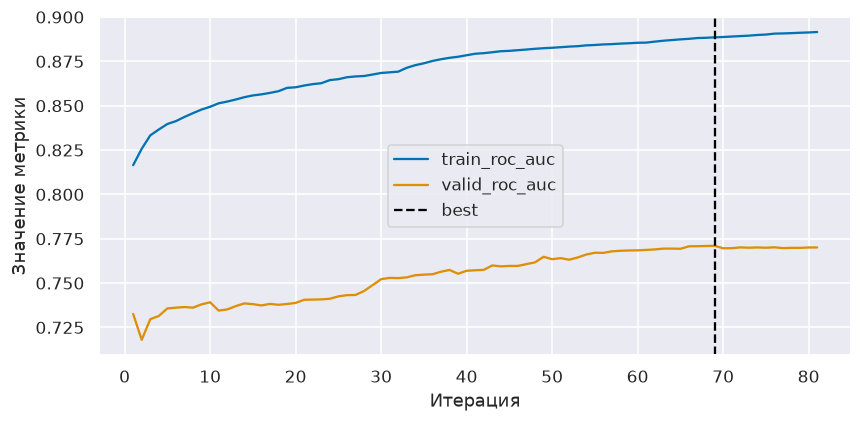

In [7]:
early = Boosting(n_estimators=250, learning_rate=1.0, base_model_params={"max_depth": 7},
                 early_stopping_rounds=12, eval_metric="valid_roc_auc", random_state=SEED, verbose=False)
start = perf_counter()
early.fit(X_train, y_train, eval_set=(X_valid, y_valid), use_best_model=True)
register("early_stopping", early, X_valid, perf_counter() - start)
print("Лучшая итерация (с 1):", early.best_iteration_ + 1,
      "; проверено итераций:", len(early.history["valid_loss"]),
      "; сохранено деревьев:", early.n_estimators_)
assert early.n_estimators_ == early.best_iteration_ + 1
assert early.n_estimators_ <= early.n_estimators
assert np.isclose(early.score(X_valid, y_valid), early.history["valid_roc_auc"][early.best_iteration_])
early.plot_history(["train_roc_auc", "valid_roc_auc"])
plt.axvline(early.best_iteration_ + 1, color="black", linestyle="--", label="best")
plt.legend(); plt.show()


Остановка отсчитывает раунды без улучшения лучшего достигнутого значения, включая плато.
ROC-AUC максимизируется, loss минимизируется. История содержит все проверенные итерации;
`use_best_model=True` восстанавливает ансамбль с лучшей итерации, а не просто последние
`patience` деревьев. Для DART сохраняются также веса ансамбля в этот момент.


**Наблюдение.** С ранней остановкой valid AUC вырос до 0.7710. На графике train продолжает улучшаться после пика valid; сохранены 69 деревьев из 81 проверенного.


### 📌 2.2. Категории 2.0 (0.5 балла)

Пока что для простоты картины мы игнорировали категориальные признаки. <font color='#c4bf0a'>**CatBoost**</font> в частности предлагает один из самых эффективных и быстрых вариантов кодировки категорий, который мы попробуем повторить

> Основная идея в том, что важны не сами категории, а значения целевой переменной, которые имеют объекты этой категории. Каждый категориальный признак мы заменим средним значением целевой переменной по всем объектам этой же категории:

$$
g_j(x, X) = \frac{\sum_{i=1}^{\ell} [f_j(x) = f_j(x_i)][y_i = +1]}{\sum_{i=1}^{\ell} [f_j(x) = f_j(x_i)]}
$$


Добавьте в модель вот это:
- `cat_features: Iterable | None` — категориальные признаки для кодирования
- `_cat_fit(self, X: np.array, y: np.ndarray)` — внутренний метод для построения счетчиков
- `_cat_transform(self, X: np.ndarray)` — внутренний метод для применения счетчиков

Лмбо сделайте энкодер отдельным классом с аналогичными методами `fit` и `transform`, это даже лучше. Его нужно прогнать всего раз для каждой из выборок

<div align="center">

<table>
<tr>
<td align="center"><b><font color="#2f82d4">XGBoost</font></b></td>
<td align="center"><b><font color="#53c96c">LightGBM</font></b></td>
<td align="center"><b><font color="#c4bf0a">CatBoost</font></b></td>
</tr>
<tr>
<td align="center"><code>-</code></td>
<td align="center"><code>-</code></td>
<td align="center"><code>cat_features</code></td>
</tr>
</table>

</div>

Закодируйте переменные, которые вы хотите считать категориальными, с помощью счётчиков (готовые реализации брать нельзя) и покажите эффект. Помните, что все должно быть векторизовано и красиво

In [8]:
feature_names = X.columns.tolist()
cat_names = ["region", "race", "empstat", "occ", "occupation"]
cat_features = [feature_names.index(c) for c in cat_names]
X_train = X.loc[train_mask].to_numpy()[train_permutation]
X_valid = X.loc[valid_mask].to_numpy()
X_test = X.loc[test_mask].to_numpy()
print("Категориальные признаки:", cat_names)

# Единый бюджет сравнений в части 2; меняем только исследуемую опцию.
COMMON = dict(n_estimators=70, learning_rate=0.3, random_state=SEED, verbose=False,
              base_model_params={"max_depth": 5, "min_samples_leaf": 30})

def experiment(name, **overrides):
    params = {**COMMON, "cat_features": cat_features, **overrides}
    model = Boosting(**params)
    start = perf_counter()
    model.fit(X_train, y_train, eval_set=(X_valid, y_valid))
    register(name, model, X_valid, perf_counter() - start)
    return model


Категориальные признаки: ['region', 'race', 'empstat', 'occ', 'occupation']


,region,age,year,race,sch,empstat,occ,annhrs,hrwage,incwage,occupation
0,0.519696,37.0,2009.0,0.517170,16.0,0.517147,0.023985,22.0,22.0,22.0,0.293665
1,0.513891,29.0,2009.0,0.517170,16.0,0.517147,0.315280,10.0,10.0,10.0,0.615562
2,0.528834,26.0,2009.0,0.562263,13.0,0.517147,0.790210,38.0,38.0,38.0,0.615562
3,0.519696,28.0,1981.0,0.517170,13.0,0.432404,0.897959,6.0,6.0,6.0,0.818128
4,0.527928,54.0,1999.0,0.517170,13.0,0.517147,0.821918,11.0,11.0,11.0,0.818128


,model,iterations,seconds,train_auc,valid_auc,valid_logloss
2,categories_plain,70,43.16644,0.88231,0.79619,0.54608


,model,iterations,seconds,train_auc,valid_auc,valid_logloss
3,numeric_control,70,36.86915,0.84292,0.73207,0.60611


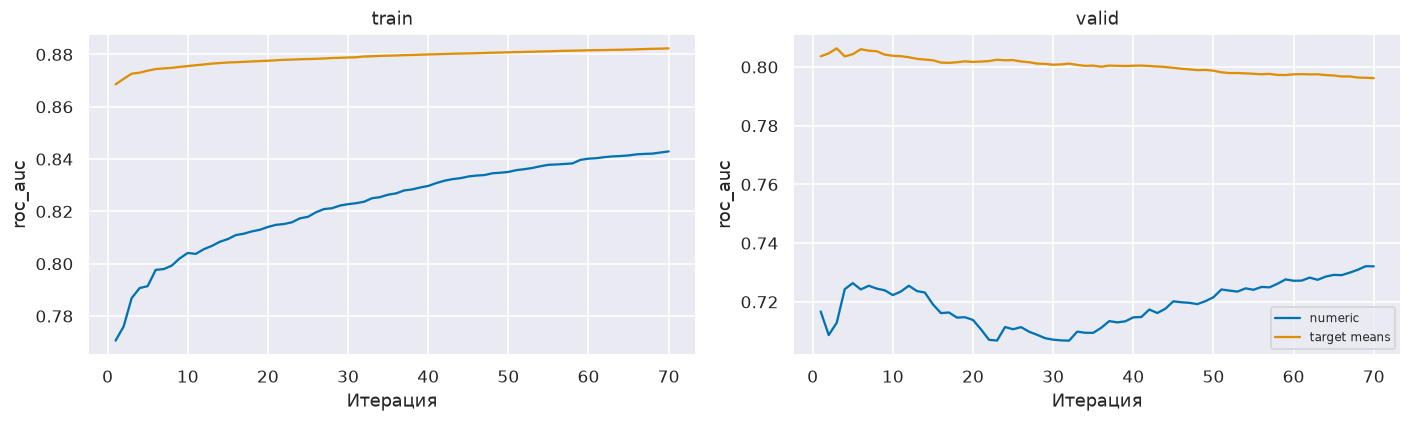

In [9]:
# Сначала именно обычные средние из пункта 2.2; утечку устраним следующим пунктом.
plain_encoder = TargetEncoder(cat_features, ordered=False).fit(X_train, y_train > 0)
encoded_preview = plain_encoder.transform(X_train[:5])
display(pd.DataFrame(encoded_preview, columns=feature_names))
cat_plain = experiment("categories_plain", ordered=False)
# Чтобы отделить эффект категорий от изменения learning_rate, тот же бюджет без occupation.
start = perf_counter()
numeric_control = Boosting(**COMMON).fit(X_train_numeric, y_train,
                                         eval_set=(X_valid_numeric, y_valid))
register("numeric_control", numeric_control, X_valid_numeric, perf_counter() - start)
compare_curves({"numeric": numeric_control, "target means": cat_plain})


**Наблюдение.** При одинаковом бюджете добавление категорий повысило valid AUC с 0.7321 до 0.7962, то есть на 0.0641. Особенно информативен категориальный код профессии.

### 💠 2.3. Категории 3.0 (0.5 балла)

Увы, закодированные признаки сами по себе являются классификаторами и, обучаясь на них, мы допускаем утечку целевой переменной в признаки, но с этим можно жить, в частности $\text{OrderedBoosting}$ это одна из главных фишек <font color='#c4bf0a'>**CatBoost**</font>, была. Почитайте [статью](https://arxiv.org/pdf/1706.09516), она интересная

Реализуйте подсчет счетчиков так, чтобы кодировка категории была только по объектам. расположенным выше в датасете (например, если выборка отсортирована каким-либо образом)

Методы добавлять не нужно, разве что очень хочется, предполагается, что это дефолтное поведение бустинга

,model,iterations,seconds,train_auc,valid_auc,valid_logloss
4,categories_ordered,70,75.52379,0.87709,0.80137,0.53984


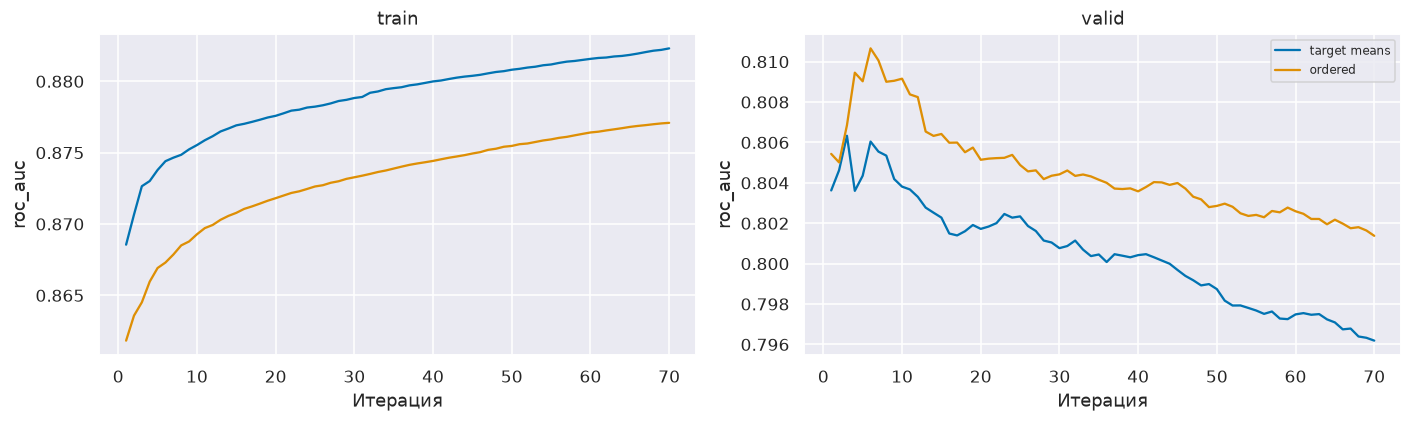

Проверка отсутствия утечки: OK


Train AUC одного счётчика region, исходный порядок: 0.9995557281636727
Train AUC region после независимой перестановки: 0.5143676581400254


In [10]:
cat_ordered = experiment("categories_ordered")
compare_curves({"target means": cat_plain, "ordered": cat_ordered})
toy_X = np.array([["a"], ["a"], ["b"], ["a"]])
toy_y = np.array([1, 0, 0, 1])
toy_encoded = TargetEncoder([0]).fit_transform(toy_X, toy_y).ravel()
assert np.allclose(toy_encoded, [.5, .75, .5, .5])
# Замена будущих меток не меняет кодировки текущих и предыдущих объектов.
changed = TargetEncoder([0]).fit_transform(toy_X, [1, 0, 1, 0]).ravel()
assert np.allclose(toy_encoded[:3], changed[:3])
print("Проверка отсутствия утечки: OK")

# Почему необходимо перемешивание именно этого файла: порядок зависит от целевой метки.
raw_train = X.loc[train_mask].to_numpy()
raw_target = y.loc[train_mask].to_numpy() > 0
raw_ordered = TargetEncoder(cat_features).fit_transform(raw_train, raw_target)
shuffled_ordered = TargetEncoder(cat_features).fit_transform(X_train, y_train > 0)
region_j = feature_names.index("region")
print("Train AUC одного счётчика region, исходный порядок:", roc_auc_score(raw_target, raw_ordered[:, region_j]))
print("Train AUC region после независимой перестановки:", roc_auc_score(y_train > 0, shuffled_ordered[:, region_j]))


На train кодировка строки равна $(S_{<i}+0.5)/(N_{<i}+1)$: текущая метка
и будущие строки не участвуют. Для valid/test берутся средние только по train;
неизвестная категория получает фиксированный prior 0.5. Это ordered target statistics,
но **не полная реализация Ordered Boosting CatBoost**: градиенты всё ещё считает
обычный ансамбль. Train-кривые для ordered encoding отражают его обучающее представление.

Исходный файл упорядочен по `sex`: сначала +1, затем -1. Поэтому статистики
префиксов в исходном порядке косвенно кодируют позицию в группе меток и дают
ложно высокий train AUC. После разбиения по годам train один раз перемешан
независимой от y перестановкой с seed=69; X и y перемещены одинаково. Внутри
этого порядка счётчик использует строго предыдущие объекты. Valid и test не
перемешиваются и не участвуют в построении счётчиков.


**Наблюдение.** Ordered-кодировка улучшила valid AUC до 0.8014 и немного уменьшила train AUC. Её максимум на valid достигается раньше конца обучения; это ещё один аргумент в пользу early stopping.


### 💠 2.4. Категории 4.0, L2 и боль (2 балла)

Но погодите, вы ещё ничего не видели! Счётчики это замечательный способ кодирования категорий, но у них есть ровно один недостаток — после кодировки признаки становятся числовыми, а если вы помните дз5, категориальные и числовые признаки обрабатываются деревьями чуть-чуть иначе.

<font color="#53c96c">**LightGBM**</font> и <font color="#2f82d4">**XGBoost**</font> решают этот вопрос не так, как <font color='#c4bf0a'>**CatBoost**</font>. Сейчас будем разбираться... И будет это тяжело, потому что отдебажить это не получится вплоть до самого конца.

Для этого пункта вам придётся стряхнуть пыль с вашей [реализации дерева](https://github.com/esokolov/ml-course-hse/blob/master/ml1-2026-spring/homework-practice/homework-practice-05-trees/hw5code.py) из дз5. Будем верить, что она написана красиво и хорошо масштабируется на новые МЛьные приключения.

#### 2.4.1. Настоящий критерий информативности (0.5 балла)

Современные реализации бустинга не используют дефолтные критерии информативности, вроде энтропии или дисперсии. Параметр `gamma`, который за нас любезно подбирается в классе `Boosting` это немного устаревший способ выбора весов (лет так на 25).

На лекции обсуждается, что получить формулу для обучения нового дерева $b_n(x)$ можно, если разложить исходную задачу обучения бустинга в ряд Тейлора. Там же показано, что при обучении на один лишь сдвиг $s_i(x)$ мы полагаем кривизну $h_i(x) = \frac{\partial^2 L}{\partial z^2}$ константной. Но можем и не полагать, как [сделали](https://arxiv.org/pdf/1603.02754) авторы уже немолодого <font color="#2f82d4">**XGBoost**</font>.

Критерий информативности в таком случае имеет вид:

$$
H(R_m) = \frac{G_l^2}{H_l + \lambda} + \frac{G_r^2}{H_r + \lambda} - \frac{G_m^2}{H_m + \lambda}
$$

- $G$ — сумма градиентов
- $H$ — сумма гессианов
- $\lambda$ — коэффициент регуляризации
- индексы $_l$, $_r$, $_m$ — левый, правый, исходный узел дерева соответственно

> Кривизна позволяет нам подстроиться под каждый объект, когда мы делаем шаг градиентного бустинга. $\gamma$ в таком случае оказывается не нужна, она не умеет подстраивать шаг индивидуально. Более того, сюда можно сразу же встроить $L_2$ регуляризацию, что мы и сделаем.     
Наконец, если перейти от объектов к градиентам и гессианам, внезапно можно вообще забить на то, числовой признак или категориальный, мы же всё равно оцениваем градиент, то есть сплит подбираем напрямую из задачи. Велико!

Текущая задача: модифицировать функцию `find_best_split`. Считайте, что параметры `grad_vector` и `hess_vector` в неё уже передаются. Градиент мы считать уже умеем, с гессианом разберёмся попозже

In [11]:
# Векторизованный поиск порога по накопленным суммам градиентов и гессианов.
toy_feature = np.array([1., 2., 3., 4., 5.])
toy_grad = np.array([1., 1., -.5, -1., -1.])
toy_hess = np.full(5, .25)
thresholds, gains, threshold, gain = find_best_split(toy_feature, toy_grad, toy_hess, l2=1)
display(pd.DataFrame({"threshold": thresholds, "gain": gains}))
print("Лучший порог:", threshold, "gain:", gain)


,threshold,gain
0,1.5,1.813889
1,2.5,6.126984
2,3.5,3.841270
3,4.5,0.813889


Лучший порог: 2.5 gain: 6.126984126984127


Разбиения оцениваются по $G_L^2/(H_L+\lambda)+G_R^2/(H_R+\lambda)-G^2/(H+\lambda)$.
Для числового признака сортируем значения и перебираем только границы между различными
значениями с соблюдением `min_samples_leaf`. Общий множитель 1/2 не влияет на выбор сплита.


#### 2.4.2. Я посадил дерево (0.75 балла)

Теперь, когда критерий у нас есть, наступает следующий логический шаг - пихнуть его в дерево. Предсказания будут иметь следующий вид:

$$b(R) = \frac{1}{|R|}\sum_{y_i \in R} \frac{\nabla(y_i)}{(\nabla^2(y_i) + \lambda )}$$

Это сумма градиентов делить на сумму гессианов + коэффициент регуляризации. В случае $\nabla^2(y_i) = 1$ и нулевой регуляризации вырождается в наш самый обыкновенный бустинг. Мы ведь помним, что каждое дерево в нём обучается на антиградиент.

Что делать то?

- добавить параметр `l2: float | None = 1.0` в вашу реализацию дерева
- подправить предсказания по формуле выше, сейчас они считаются для классификации, а не для регрессии (должно быть идентично и для чисел, и для категорий)
- категории нужно занумеровать, это делается за вас в дереве, но не забудьте пожалуйста
- в `fit_node` должны поступать градиенты и гессианы, в левый и правый узел после разбиения тоже, уже для соответствующих левой и правой подвыборок

> Строго говоря, <font color="#53c96c">**LightGBM**</font> перебирает категории по критерию Фишера, который группирует категории по градиентам. Это один из видов квантизации, которая будет чуть ниже. Делать это не надо, но если любопытно, то [почитайте](https://lightgbm.readthedocs.io/en/latest/Features.html#optimal-split-for-categorical-features)

In [12]:
# Проверяем нативные категории: дерево само ранжирует категории по G/(H+lambda).
newton_tree = NewtonTreeRegressor(max_depth=3, l2=3, cat_features=cat_features, random_state=SEED)
newton_tree.fit(X_train[:15000], -cat_ordered.grad_fn(y_train[:15000], np.zeros(15000)),
                hess_vector=np.full(15000, .25))
print("Предсказания Newton tree:", newton_tree.predict(X_valid[:8]))
print("Число признаков:", newton_tree.n_features_in_)


Предсказания Newton tree: [ 1.61398896 -0.19144603 -0.05063291 -1.33302369  1.61398896  1.61398896
 -0.78515186  1.61398896]
Число признаков: 11


В формуле листа в условии есть противоречие: среднее отдельных отношений не равно
отношению сумм. Из минимизации квадратичного приближения следует
$w_R=-\sum g_i/(\sum h_i+\lambda)$. Здесь в дерево передаётся антиградиент,
поэтому в коде числитель положительный. Регуляризация добавляется один раз на лист.
Категории сортируются по агрегированному $G/(H+\lambda)$ в каждом узле;
это допускает групповые, а не произвольные числовые разбиения кодов категорий.


#### 2.4.3. Момент истины (0.75 балла)

Наконец, осталось запихнуть это дело в бустинг. Алгоритм будет работать точно так же. Если вы корректно его написали, поменять потребуется немного, а именно:

- добавить гиперпараметр `l2: float | None = 0.0`
- добавить метод `self.hess_fn = lambda y, z: ...`, который будет считать гессиан для бинарной кросс-энтропии
- приравнять оптимальную гамму к единице, если `l2` не равен 0
- передавать гредиенты и гессианы в базовую модель, если у неё есть параметр `l2` и он не равен 0
- гессиан лучше клипать, иначе можно внезапно поделить на 0 при маленьком `l2`
- не забудьте, что передавать надо антиградиенты, а не просто градиенты, иначе выйдет что-то не то

Покажите, что оно работает...

,model,iterations,seconds,train_auc,valid_auc,valid_logloss
5,newton_l2,35,59.61887,0.88407,0.7406,0.70816


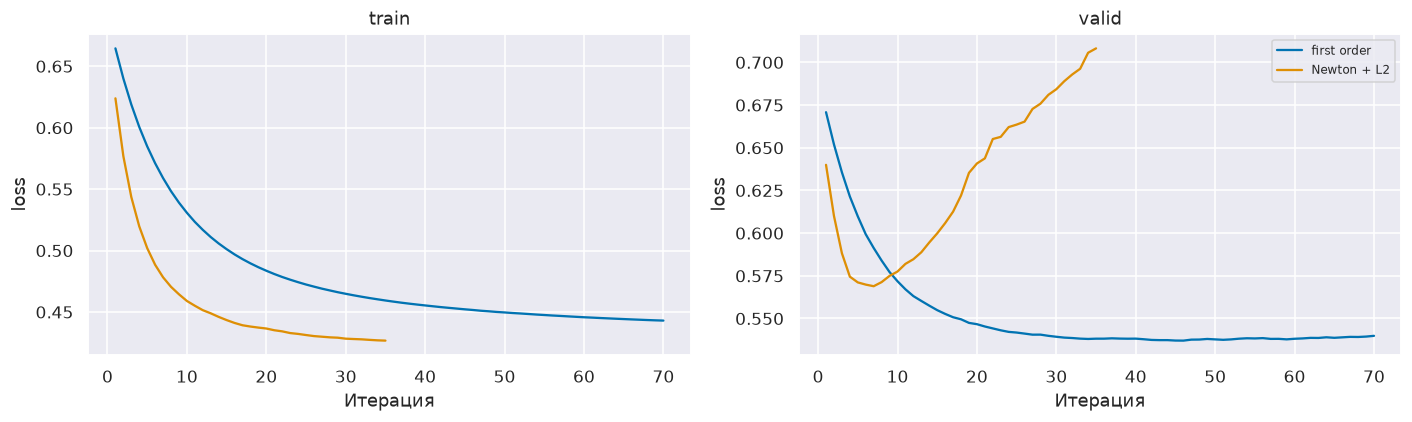

In [13]:
newton = experiment("newton_l2", base_model_class=NewtonTreeRegressor,
                    base_model_params={"max_depth": 3, "min_samples_leaf": 50},
                    n_estimators=35, learning_rate=.2, l2=5, subsample=.6)
assert np.allclose(newton.gammas, 1)
compare_curves({"first order": cat_ordered, "Newton + L2": newton}, "loss")


Newton-вариант использует нативные категории, вторые производные и более мелкие деревья;
это демонстрация совместной работы реализации, а не изолированная оценка эффекта L2.
Гессианы ограничены снизу 1e-8, гамма равна 1. Для чистого сравнения L2 в готовой
реализации ниже фиксируются все остальные параметры.


**Наблюдение.** Newton-вариант в выбранной конфигурации дал valid AUC 0.7406, хуже первого порядка (0.8014). Его valid BCE равна 0.7082. Математическая корректность второго порядка не гарантирует улучшения на временном разбиении; здесь одновременно меняются обработка категорий, глубина и шаг.


### 💠 2.5. Бутстрап (1.25 балла)</span>

Как известно, при обучении базовых алгоритмов в беггинге, используется бутстрапированная выборка. Звучит хайпово, почему бы не попробовать сделать то же самое в бустинге?

> Идея, которая за этим стоит проста — бустинги переобучаются, как черти. Бутстрап же может сделать процесс куда более робастным и быть одним из способов регуляризации, а заодно уменьшить время обучения, в случае бутстрапа Бернулли

#### 2.5.1. Бутстрап дефолтный (0.75 балла)

Вам нужно реализовать параметры:
- `subsample: float = 1.0` — доля объектов, на которой будет обучаться базовая модель (какую часть составляет бутстрапная выборка от исходной обучающей). Соответствует бутстрапу типа `Bernoulli`. Каждый объект либо входит в подвыборку, либо нет
- `bagging_temperature: float = 1.0` — температура для генерации весов. Соответствует бутстрапу типа `Bayesian`. Каждому объекту присваивается вес $w$, который получается из температуры $t$, после чего объект, в количестве $w$, попадает в выборку.      
$w = (-\log(X))^t$, где $X \sim {U[0, 1]}$      
Таким образом можно сделать симуляцию повторений, обобщив на непрерывный случай. Обычный бутстрап не умеет сэмплировать дробное число объектов, но можно сделать примерно то же самое, если размножить объект $w$ раз, либо присвоить вес. Подумайте, как это корректно реализовать в бустинге
- `bootstrap_type: str | None = 'Bernoulli'` — тип бутстрапа

<div align="center">

<table>
<tr>
<td align="center"><b><font color="#2f82d4">XGBoost</font></b></td>
<td align="center"><b><font color="#53c96c">LightGBM</font></b></td>
<td align="center"><b><font color="#c4bf0a">CatBoost</font></b></td>
</tr>
<tr>
<td align="center"><code>subsample</code>, <code>-</code></td>
<td align="center"><code>subsample</code>, <code>bagging</code></td>
<td align="center"><code>subsample</code>, <code>bootstrap_type</code></td>
</tr>
</table>

</div>

<div style="border-left: 5px solid #ff748c; padding: 10px 20px 2px; margin: 15px 0 15px 20px; max-width: 800px; background-color: rgba(255, 116, 140, 0.05);">

**Вопрос:** как бутстрап может помочь в обучении с точки зрения смещения, разброса и вообще?

**Ответ:** Бутстрап уменьшает корреляцию базовых алгоритмов и обычно снижает разброс ансамбля.
На каждом шаге дерево видит меньше данных либо случайные веса, поэтому его смещение может
вырасти; последовательное исправление ошибок частично это компенсирует. Bernoulli ускоряет
обучение дерева, Bayesian сохраняет все строки и меняет их вклад через sample_weight.
Улучшение качества не гарантировано: слишком сильное сэмплирование приводит к недообучению.

</div>

,model,iterations,seconds,train_auc,valid_auc,valid_logloss
6,bernoulli,70,46.73941,0.87726,0.79914,0.54287


,model,iterations,seconds,train_auc,valid_auc,valid_logloss
7,bayesian,70,83.60797,0.87744,0.79984,0.54102


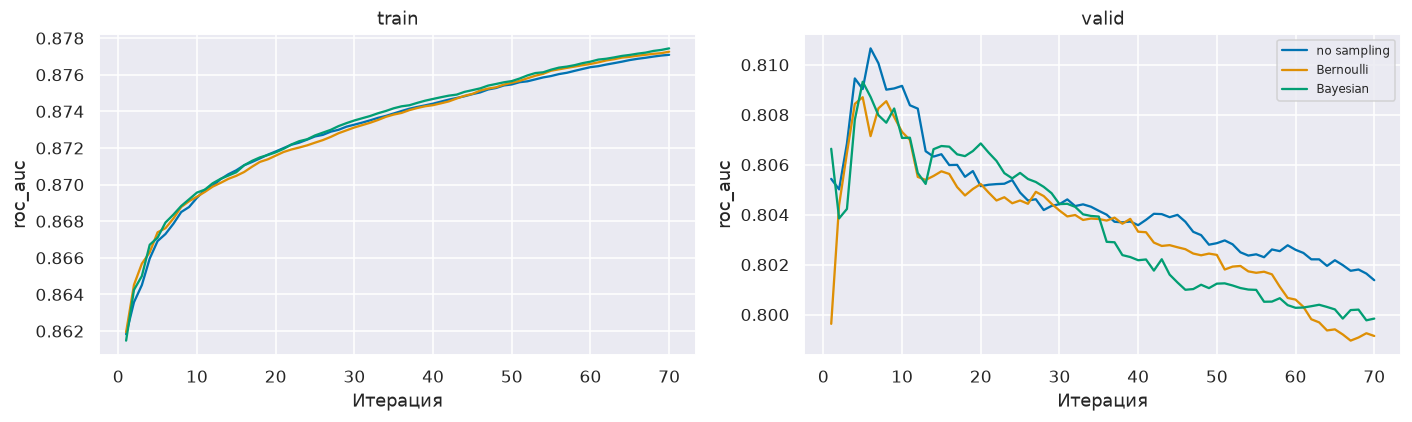

In [14]:
bernoulli = experiment("bernoulli", subsample=.6)
bayesian = experiment("bayesian", bootstrap_type="Bayesian", bagging_temperature=1.0)
compare_curves({"no sampling": cat_ordered, "Bernoulli": bernoulli, "Bayesian": bayesian})


**Наблюдение.** Bernoulli: valid AUC 0.7991, время 46.7 с; Bayesian: 0.7998, 83.6 с. Без сэмплирования: 0.8014, 75.5 с. В этом запуске Bernoulli ускоряет обучение ценой небольшой потери качества; Bayesian выигрыша не дал.

Помимо выбора случайных объектов, есть идея выбирать случайное подмножество признаков, заложенная в Random Forest. Мотивация это делать точно та же самая, что и в бутстрапировании, за это будет отвечать параметр `rsm`

В библиотеках это реализовано так:

<div align="center">

| <font color="#2f82d4">XGBoost</font> | <font color="#41a657">LightGBM</font> | <font color='#d1cd3b'>CatBoost</font> |
| :---: | :---: | :---: |
| `colsample_bytree`| `colsample_bytree`| `rsm`|

</div>

Нужно добавить параметр:
- `rsm: float = 1.0` — доля признаков, участвующих в обучении модели. Каждый признак либо входит, либо не входит в пул, на котором обучается базовый алгоритм, по аналогии с бутстрапом Бернулли

,model,iterations,seconds,train_auc,valid_auc,valid_logloss
8,rsm,70,52.02801,0.87743,0.79992,0.54007


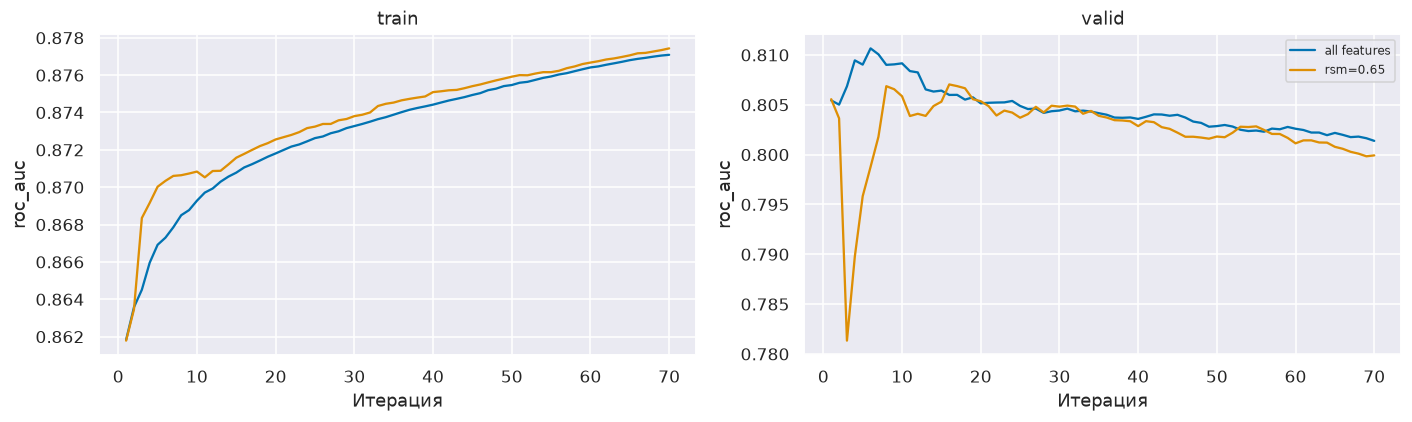

Признаки первых трёх деревьев: [[2, 4, 5, 6, 7, 8, 10], [1, 3, 4, 6, 7, 8, 9, 10], [0, 1, 2, 3, 5, 7, 8, 9]]


In [15]:
rsm_model = experiment("rsm", rsm=.65)
compare_curves({"all features": cat_ordered, "rsm=0.65": rsm_model})
print("Признаки первых трёх деревьев:", [indices.tolist() for indices in rsm_model.features_[:3]])


**Наблюдение.** RSM уменьшил время до 52.0 с, valid AUC составила 0.7999. Эффект по качеству небольшой; в таблице выше видны разные подмножества признаков для деревьев.

#### 2.5.2. GOSS (0.5 балла)

Заметим, что во время обучения не все объекты одинаково важны. Один из вариантов это исправить — ввести какие-то веса на объекты, однако можно пойти чуть хитрее. В <font color='#53c96c'>**LightGBM**</font> придумали подход [Gradient-based One-side Sampling](https://www.microsoft.com/en-us/research/wp-content/uploads/2017/11/lightgbm.pdf)

> Давайте оценивать важность объектов в отдельный момент обучения нового дерева. Будем считать, какой антиградиент привносит каждый объект. Далее разобьем градиенты на 2 группы. Объекты с большими (по модулю) градиентами берутся все, с маленькими — только часть, по аналогии с бутстрапом. И не забываем домножить на фактор, чтобы учесть выкинутые объекты. Подробнее в статье

Параметры, которые нужно сделать:

- `goss: bool = False` — GOSS бустинг или нет
- `goss_k: float = 0.2` — доля объектов, градиенты которых будем считать большими. Все остальное — маленькими
- `subsample: float = 0.3` — параметры сэмплинга Бернулли для маленьких градиентов из пункта 2.3

<div align="center">

<table>
<tr>
<td align="center"><b><font color="#2f82d4">XGBoost</font></b></td>
<td align="center"><b><font color="#53c96c">LightGBM</font></b></td>
<td align="center"><b><font color="#c4bf0a">CatBoost</font></b></td>
</tr>
<tr>
<td align="center"><code>-</code></td>
<td align="center"><code>bagging='goss'</code></td>
<td align="center"><code>bootstrap_type='MVS'</code></td>
</tr>
</table>

</div>

Сделайте и посмотрите

,model,iterations,seconds,train_auc,valid_auc,valid_logloss
9,goss,70,39.30348,0.87708,0.79693,0.54677


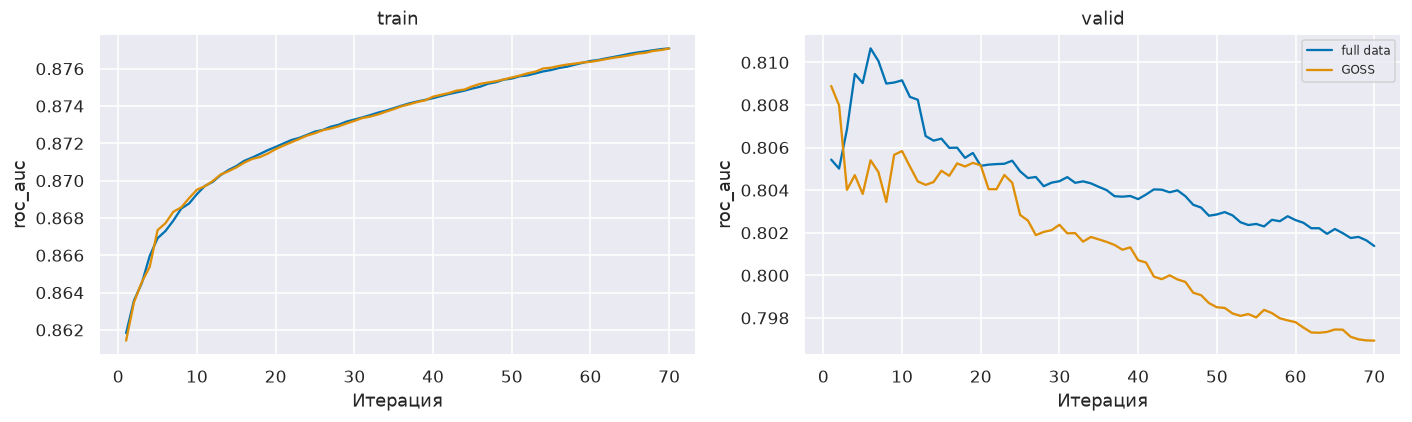

In [16]:
goss_model = experiment("goss", goss=True, goss_k=.2, subsample=.3)
compare_curves({"full data": cat_ordered, "GOSS": goss_model})


В этой реализации `subsample` — вероятность включения объекта **среди оставшихся**
малых градиентов. Поэтому поправка их веса равна $1/\text{subsample}$.
В обозначениях статьи LightGBM, где $b$ — доля малых объектов от **всей** выборки,
это то же самое, что $(1-a)/b$. Большие градиенты сохраняются все.
При равных модулях градиентов сначала применяется воспроизводимая перестановка.


**Наблюдение.** GOSS сократил время до 39.3 с против 75.5 с, valid AUC снизилась с 0.8014 до 0.7969. Для заданных долей это полезный компромисс скорости и качества, но не улучшение AUC.


### 💠 2.6. Бинаризация (1 балл)

Вместо того, чтобы выкидывать признаки, можно попробовать проредить их множество значений, применив бинаризацию. В идеале это стоит делать с датасетом до обучения модели, но не обязательно, можно, например, на этапе `fit`, а в `partial_fit` приходит уже квантизованный датасет.

> Зачем это? Да все очень просто! Квантизованные данные весят гораздо меньше, значений в них куда как меньше, а значит, наше обучение пойдет гораздо быстрее, к тому же все снова станет устойчивее.        
Беда лишь в новых данных, которые могут оказаться вне бина, но великие силы избавили нас от этих проблем в нашем датасете. Фактически мотивация вновь та же, что у бутстрапа

#### 2.6.1. Простейшие стратегии (0.5 балла)

Нужно добавить параметры:
- `quantization_type: str | None = None` — тип квантизации, если она есть
- `nbins: int = 255` — число бинов для квантизации. Игнорируем, если тип квантизации не указан

Либо сделать квантизатор отдельным классом, где в `fit` запоминаются пороги, а в `transform` преобразуются фичи

Рассмотрим варианта `quantization_type`:

- `'uniform'` — значения признака $[\min f_i, \max f_i]$ отображаются в `nbins` отрезков одинаковой длины, которые полностью покрывают интервал
- `'quantile'` — тот же самый отрезок сортируется и бьется на `nbins` квантилей от 0 до 1

<div align="center">

<table>
<tr>
<td align="center"><b><font color="#2f82d4">XGBoost</font></b></td>
<td align="center"><b><font color="#53c96c">LightGBM</font></b></td>
<td align="center"><b><font color="#c4bf0a">CatBoost</font></b></td>
</tr>
<tr>
<td align="center"><code>tree_method</code></td>
<td align="center"><code>max_bin</code></td>
<td align="center"><code>quantize(...)</code></td>
</tr>
</table>

</div>

Разницу между ними вы можете увидеть на картинке, где квантизуется гауссиана

<img src="https://i.postimg.cc/gJ2SJgpN/image-2025-11-29-201502496.png" height=300>

Реализуйте их, примените их к числовым признакам, и покажите, что все работает четко

,model,iterations,seconds,train_auc,valid_auc,valid_logloss
10,uniform,70,67.76238,0.86609,0.8306,0.50515


,model,iterations,seconds,train_auc,valid_auc,valid_logloss
11,quantile,70,74.43874,0.87693,0.80192,0.53857


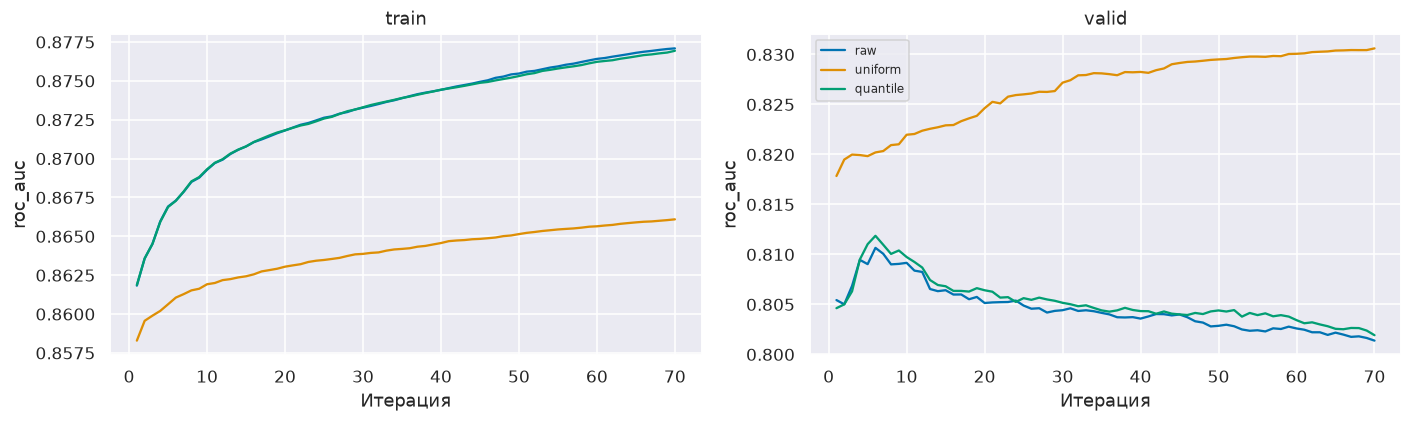

Бины признака age: [ 1.  2.  3.  4.  5.  6.  7.  8.  9. 10. 11. 12. 13. 14. 15. 16. 17. 18.
 19. 20. 21. 22. 23. 24. 25. 26. 27. 28. 29. 30. 31. 32. 33. 34. 35. 36.
 37.]


In [17]:
uniform_model = experiment("uniform", quantization_type="uniform", nbins=64)
quantile_model = experiment("quantile", quantization_type="quantile", nbins=64)
compare_curves({"raw": cat_ordered, "uniform": uniform_model, "quantile": quantile_model})
print("Бины признака age:", np.unique(quantile_model._X_train[:, feature_names.index("age")]))


**Наблюдение.** Uniform с 64 бинами дала valid AUC 0.8306, quantile — 0.8019. Прирост uniform относительно исходных чисел равен 0.0292. В этой задаче ограничение точности числовых признаков оказалось полезнее почти не изменившей результат квантильной стратегии.

<div style="border-left: 5px solid #ff748c; padding: 10px 20px 2px; margin: 15px 0 15px 20px; max-width: 800px; background-color: rgba(255, 116, 140, 0.05);">

**Вопрос:** как квантизация поможет в обработке выбросов и нанов?

**Ответ:** Квантизация ограничивает влияние величины выброса: все большие значения могут оказаться
в крайнем бине. Но выбросы растягивают диапазон uniform и расходуют бины; quantile устойчивее
к их масштабу. Пропуски квантизация сама не восстанавливает: в реализации для них выделен бин 0.

</div>

<div style="border-left: 5px solid #ff748c; padding: 10px 20px 2px; margin: 15px 0 15px 20px; max-width: 800px; background-color: rgba(255, 116, 140, 0.05);">

**Вопрос:** можно ли просто заполнить наны каким-то числом? Имеет ли значение, что это за число (-1, -100, -1e32)?

**Ответ:** Заполнять можно, но для дерева важен порядок значений. Числа -1, -100 и -1e32 эквивалентны лишь тогда, когда все они строго ниже любого наблюдаемого значения и представимы в используемом dtype. Если -1 лежит внутри диапазона, оно смешает пропуски с реальными значениями; экстремальное число может вызвать проблемы точности или переполнение. Лучше отдельный индикатор пропуска или специальный бин.

</div>

#### 2.6.2. Квантизация (0.5 балла)

В современных имплементациях бустинга используются более сложные методы квантизации. К сожалению, способы выше страдают либо от неравноправности бинов — в каких-то объектов больше, в каких-то меньше, в каких-то значения повторяются, в каких-то нет, либо от того, что целевая переменная от бинов зависит опосредованно, да и пороги берутся с потолка

Есть два необычных, но крайне интересных подхода:

1. $\text{MinEntropy}$. Это [один из методов](https://catboost.ai/docs/en/concepts/quantization), который используется для бинаризации в <font color='#c4bf0a'>**CatBoost**</font>, остальные на него очень похожи. Будем жадно набирать бины так, чтобы суммарная побиновая энтропия объектов ($\sum_{i \in \text{bin}} x_i\log(x_i)$) была как можно меньше. Это, правда, предполагает, что значения числовых фичей могут повторяться, и так и есть в части наших колонок
   
2. $\text{PiecewiseEncoding}$. Это относительно свежий метод для [табличных трансформеров](https://arxiv.org/pdf/2203.05556). Суть заключается в том, что бины для квантизации будем брать не с потолка, а именно те, что нужны для разбиения таргета через максимизацию $\text{InfoGain}$

Оба метода на самом деле похожи, поэтому выбирайте на свой вкус. Оба пытаются подобрать пороги при помощи некоторого алгоритма, который тоже работает с энтропией или InfoGain, возможно, вы его даже знаете, осталось правильно его применить. В библиотеках способы реализации чуть отличаются, и предлагаемый способ не единственный. Если есть желание - экспериментируйте!

<div align="center">

<table>
<tr>
<td align="center"><b><font color="#2f82d4">XGBoost</font></b></td>
<td align="center"><b><font color="#53c96c">LightGBM</font></b></td>
<td align="center"><b><font color="#c4bf0a">CatBoost</font></b></td>
</tr>
<tr>
<td align="center"><code>-</code></td>
<td align="center"><code>-</code></td>
<td align="center"><code>feature_border_type="Piecewise"</code></td>
</tr>
</table>

</div>

Добавьте одну из опций, `'min_entropy'` или `'piecewise'`, для `quantization_type` и покажите, что оно работает

,model,iterations,seconds,train_auc,valid_auc,valid_logloss
12,piecewise,70,74.24192,0.87711,0.80222,0.53839


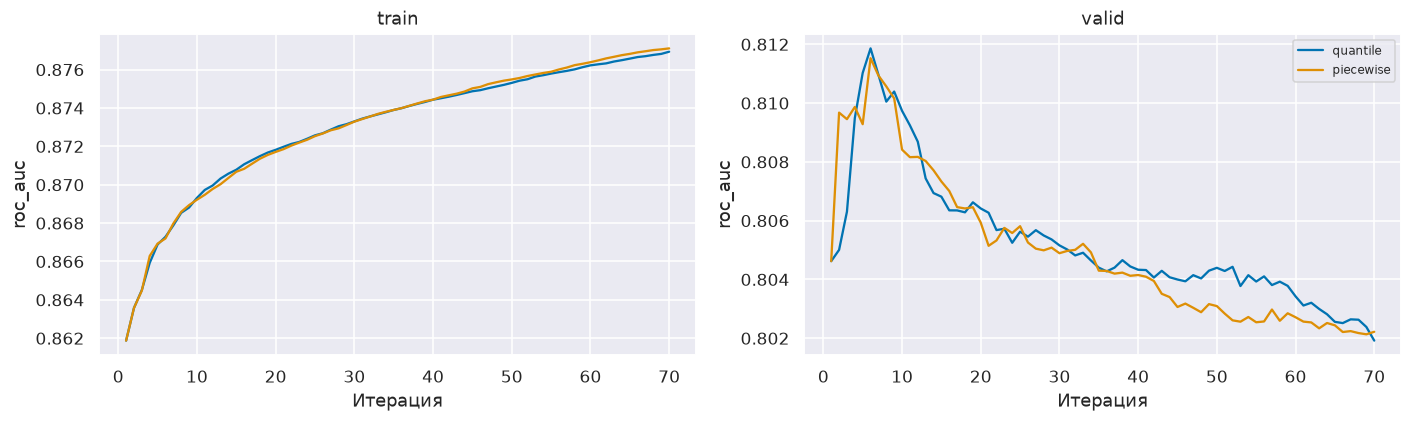

Пороги age: [25.5 27.5 28.5 29.5 30.5 31.5 32.5 33.5 34.5 36.5 37.5 38.5 39.5 40.5
 42.5 44.5 45.5 46.5 47.5 48.5 49.5 50.5 51.5 53.5 54.5 55.5 56.5 59.5
 60.5 61.5 63.5]


In [18]:
piecewise_model = experiment("piecewise", quantization_type="piecewise", nbins=32)
compare_curves({"quantile": quantile_model, "piecewise": piecewise_model})
print("Пороги age:", piecewise_model.quantizer_.borders_[feature_names.index("age")])


Реализована требуемая supervised-квантизация: одномерное дерево с критерием entropy
и ограниченным числом листьев выбирает границы по InfoGain. Пороги определяются
только по train. Здесь используется номер интервала, как предлагает задание;
полное Piecewise Linear Encoding из статьи дополнительно интерполирует значение
внутри интервала и создаёт вектор признаков. Категориальные счётчики не квантизуются.
NaN получает отдельный бин 0; значения за пределами train попадают в крайние бины.


**Наблюдение.** Границы по InfoGain дали valid AUC 0.8022: близко к quantile и ниже uniform. Использование таргета для подбора границ само по себе не гарантирует улучшения на будущем годе.


### 💠 2.7. Важность дерева (0.5 балла)

Поскольку наша базовая модель — это дерево из `sklearn`, мы можем вычислить важность признака отдельно для каждого дерева и взвешенно усреднить (воспользуйтесь `feature_importances_` у `DecisionTreeRegressor` и знанием о гаммах), после этого нормировать значения, чтобы они суммировались в единицу (обратите внимание, что они должны быть неотрицательными — иначе вы что-то сделали не так).

> Как правило, этот способ учитывает, сколько раз та или иная фича использовалась для сплита. Чем больше раз, тем этот признак важнее

Допишите к бустингу:
- `get_feature_importance(self, X: np.ndarray | None = None, y: np.ndarray | None = None, type="split")` — атрибут, который возвращает важность признаков, согласно методу выше

<div align="center">

<table>
<tr>
<td align="center"><b><font color="#2f82d4">XGBoost</font></b></td>
<td align="center"><b><font color="#53c96c">LightGBM</font></b></td>
<td align="center"><b><font color="#c4bf0a">CatBoost</font></b></td>
</tr>
<tr>
<td align="center"><code>model.get_score()</code></td>
<td align="center"><code>lightgbm.importance()</code></td>
<td align="center"><code>model.get_feature_importance()</code></td>
</tr>
</table>

</div>

Покажите, какие признаки оказались самыми важными

,split
feature,
occ,0.647148
occupation,0.127240
year,0.051776
sch,0.032213
incwage,0.030533
annhrs,0.030077
age,0.029117
hrwage,0.023141
race,0.017302


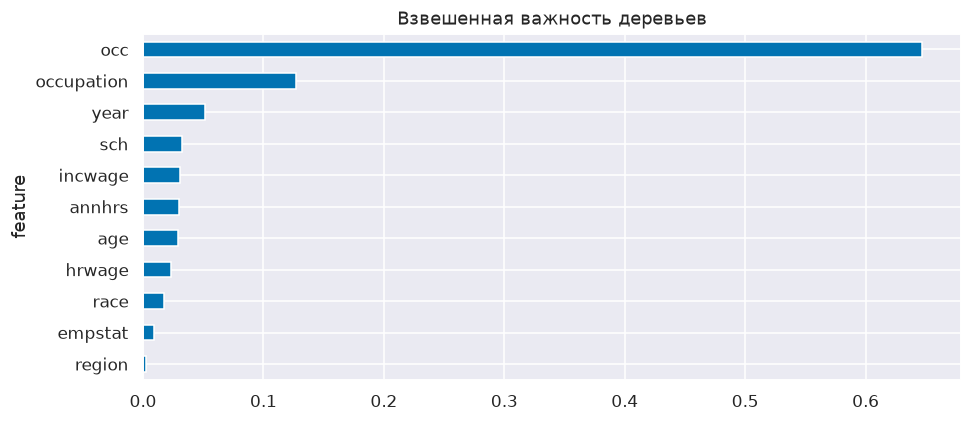

In [19]:
split_importance = cat_ordered.get_feature_importance()
assert np.all(split_importance >= 0) and np.isclose(split_importance.sum(), 1)
importance_table = pd.DataFrame({"feature": feature_names, "split": split_importance}).set_index("feature")
display(importance_table.sort_values("split", ascending=False))
importance_table.sort_values("split").plot.barh(legend=False, title="Взвешенная важность деревьев")
plt.tight_layout(); plt.show()


**Наблюдение.** По MSE-важности лидируют `occ` (около 64.7%) и `occupation` (12.7%). Код профессии важнее укрупнённого названия профессиональной группы.

### 💠 2.8. Важность бустинга (1 балл)

Но бустинг и дерево это, как говорится, две большие разницы. Дерево ничего не знает про лосс, оно учится по другим соображениям, которые на самом деле не так важны. И как оказывается, это влияние на лосс можно оценить.

> Проблема предыдущего способа в том, что мы не учитываем, насколько сплит реально помогает в решении задачи минимизации функции потерь. Но зная лосс, а точнее градиент, это можно элементарно оценить

Алгоритм будет такой:
1. Возьмём базовый эстимейтор $b_k$ (`sklearn.tree.DecisionTreeRegressor`)
2. Научимся доставать из него [путь](https://scikit-learn.org/stable/auto_examples/tree/plot_unveil_tree_structure.html) для конкретного объекта $x_i$
3. В этом пути для каждого узла $R_j$ вытащим предсказание $b_k(R_j)(x_i)$ (это параметр `value`) и то, по какой фиче был сделан сплит
4. Для каждого предсказания запишем, на сколько уменьшился лосс (проще всего взять антиградиент, но можно взять критерий информативности из 2.4.1)
   
Повторить для всех деревьев, для всех объектов (или осмысленного их сабсэмпла)

Допишите к бустингу:
- `get_feature_importance(self, X: np.ndarray, y: np.ndarray, type="gain")` — атрибут, который возвращает важность признаков, согласно методу выше

Изменилось ли что-то в важности признаков?

,split,gain
feature,,
occ,0.647148,0.904532
occupation,0.127240,0.073203
year,0.051776,0.011763
sch,0.032213,0.008857
race,0.017302,0.000858
empstat,0.009353,0.000737
region,0.002099,0.000050
age,0.029117,0.000000
annhrs,0.030077,0.000000


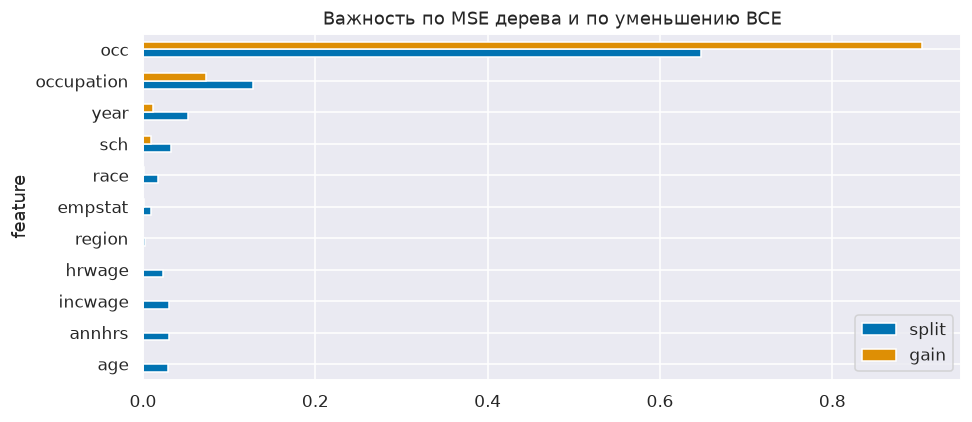

Spearman correlation: 0.5862050525510366


In [20]:
# Осмысленная подвыборка валидации: чужие метки не входят в категориальные счётчики.
importance_rows = np.random.default_rng(SEED).choice(len(X_valid), 10000, replace=False)
gain_importance = cat_ordered.get_feature_importance(X_valid[importance_rows], y_valid[importance_rows], type="gain")
importance_table["gain"] = gain_importance
display(importance_table.sort_values("gain", ascending=False))
importance_table.sort_values("gain").plot.barh(title="Важность по MSE дерева и по уменьшению BCE")
plt.tight_layout(); plt.show()
print("Spearman correlation:", importance_table.corr(method="spearman").iloc[0, 1])


Название `split` оставлено из условия, но `feature_importances_` sklearn на самом деле
суммирует взвешенное уменьшение impurity (MSE), а не число сплитов.
В `gain` для каждого объекта берётся путь по дереву и точная разность BCE между
предсказаниями дочернего и родительского узлов с учётом текущего ансамбля и шага.
Вклад относится к признаку родительского сплита; отрицательный итог по признаку
обрезается до нуля перед нормировкой. Это оценка на заданной выборке, не SHAP
и не причинная интерпретация.


**Наблюдение.** По уменьшению BCE на подвыборке valid на `occ` приходится около 90.5% нормированной положительной важности, на `occupation` — 7.3%. Spearman-корреляция двух ранжирований — 0.586. Вклад возраста и трёх денежных/часовых колонок здесь обрезан до нуля: их суммарные изменения BCE на valid оказались неположительными. Это не утверждение об отсутствии связи вообще.


### 💠 2.9. DART (1 балл)

Ранее мы обсуждали, что каждый базовый алгоритм пытается исправить ошибки всего предыдущего ансамбля. Из-за этого возникает неравноправие — каждая новая модель вносит все меньший и меньший вклад. Уверенные обучатели нейросетей знают, что это может привести к переобучению, если проводить аналогию с весами. Но выход есть, и выход этот [DART](https://arxiv.org/pdf/1505.01866)!

> В DL есть такой вид регуляризации, как dropout, когда некоторые узлы нейросети со случайным шансом отключаются. Можно попробовать обобщить этот подход на случай бустингов и случайно выкидывать деревья из композиции во время обучения

1. Выбираем, какие деревья убрать. При подсчете антиградиента берем не весь ансамбль, а только ту часть, что осталась
2. Домножаем выходы дерева на $1/k$, где $k$ — число удаленных деревьев, чтобы учесть тот факт, что ансамбль был не весь. Тогда вклад отдельного дерева будет не настолько большим
3. Домножаем выходы выкинутых деревьев на $k/(k+1)$, чтобы масштабы выходов примерно совпадали

Параметры, которые нужно добавить:

- `dart: bool = False` — DART бустинг или нет
- `dropout_rate: float = 0.05` — доля деревьев, которую выкидываем во время обучения DART

<div align="center">

<table>
<tr>
<td align="center"><b><font color="#2f82d4">XGBoost</font></b></td>
<td align="center"><b><font color="#53c96c">LightGBM</font></b></td>
<td align="center"><b><font color="#c4bf0a">CatBoost</font></b></td>
</tr>
<tr>
<td align="center"><code>XGBClassifier(booster="dart")</code></td>
<td align="center"><code>LGBMClassifier(boosting_type="dart")</code></td>
<td align="center"><code>-</code></td>
</tr>
</table>

</div>

Попробуйте обучить DART на наших данных. Статью читать настоятельно рекомендуется, метод не самый простой

,model,iterations,seconds,train_auc,valid_auc,valid_logloss
13,dart,70,75.19736,0.86957,0.80785,0.58419


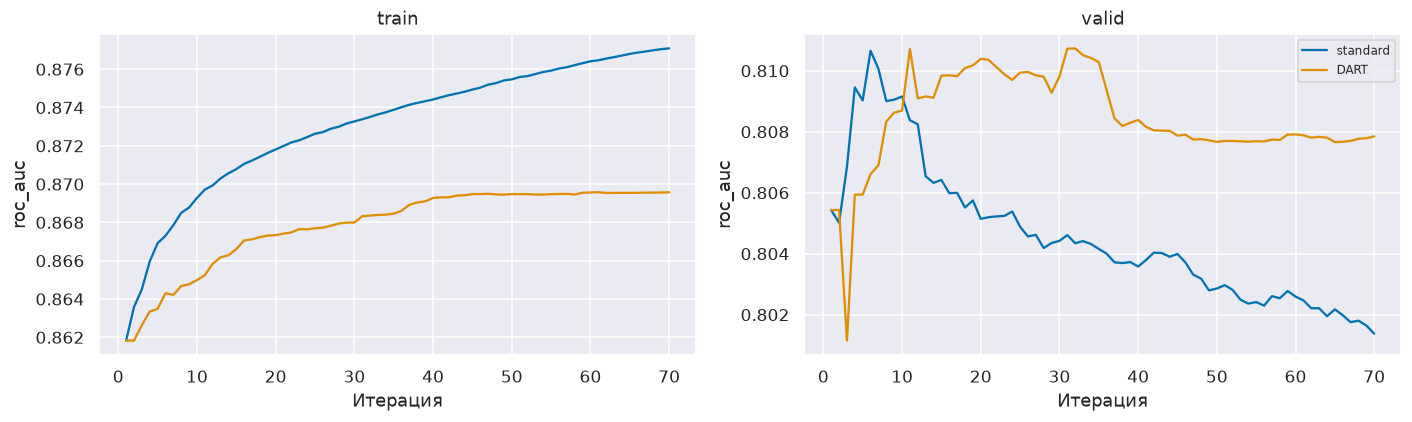

Первые гаммы DART: [0.0194 0.0694 0.08   0.1185 0.0591 0.0356 0.0273 0.15   0.038  0.0737]


In [21]:
dart_model = experiment("dart", dart=True, dropout_rate=.1)
compare_curves({"standard": cat_ordered, "DART": dart_model})
print("Первые гаммы DART:", np.round(dart_model.gammas[:10], 4))


DART выбирает деревья для временного удаления перед вычислением антиградиента.
Если их $k>0$, новое дерево получает множитель $1/k$, затем и оно, и удалённые
получают $k/(k+1)$; итоговый множитель нового дерева равен $1/(k+1)$.
Общий `learning_rate` применяется к итоговой сумме. Предсказание детерминировано:
при inference используются все сохранённые деревья. В отличие от обычного бустинга,
train loss не обязан монотонно убывать из-за изменения прежних весов.


**Наблюдение.** DART дал valid AUC 0.8078 против 0.8014. При этом его BCE 0.5842 хуже обычного варианта (0.5398): лучшее ранжирование не обязательно означает более точные вероятности.


### 💠 2.10. Бустинг линейных моделей (0.5 балла)

<div style="border-left: 5px solid #ff748c; padding: 10px 20px 2px; margin: 15px 0 15px 20px; max-width: 800px; background-color: rgba(255, 116, 140, 0.05);">

**Вопрос:** что произойдет при ансамблировании линейных моделей? Имеет ли это смысл?

**Ответ:** Сумма линейных функций остаётся линейной: sum(a_k^T x+b_k) = a^T x+b.
Бустинг линейных регрессоров не создаёт нелинейные взаимодействия и не расширяет семейство
линейных разделяющих поверхностей. Он имеет смысл как другой способ оптимизации логистической
потери и пошагового ограничения модели, но обучение одного линейного классификатора обычно проще.

</div>

Давайте убедимся. Обучите бустинг, где в качестве базовой модели будет линейная регрессия. Обязательно сохраните историю функции потерь и зафиксируйте время обучения. Можно взять уже готовый из <font color='#2f82d4'>**XGBoost**</font>, но будьте готовы разобраться с тем, как оттуда достать историю обучения

<div align="center">

<table>
<tr>
<td align="center"><b><font color="#2f82d4">XGBoost</font></b></td>
<td align="center"><b><font color="#53c96c">LightGBM</font></b></td>
<td align="center"><b><font color="#c4bf0a">CatBoost</font></b></td>
</tr>
<tr>
<td align="center"><code>XGBClassifier(booster="gblinear")</code></td>
<td align="center"><code>-</code></td>
<td align="center"><code>-</code></td>
</tr>
</table>

</div>

In [22]:
from sklearn.linear_model import LinearRegression, SGDClassifier, LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

# Единая матрица для обеих линейных моделей. Ordered encoding — только на train.
linear_encoder = TargetEncoder(cat_features)
linear_train = linear_encoder.fit_transform(X_train, y_train > 0)
linear_valid = linear_encoder.transform(X_valid)
scaler = StandardScaler().fit(linear_train)
linear_train = scaler.transform(linear_train)
linear_valid = scaler.transform(linear_valid)
linear_boost = Boosting(base_model_class=LinearRegression, n_estimators=100,
                        learning_rate=.5, random_state=SEED, verbose=False)
start = perf_counter()
linear_boost.fit(linear_train, y_train, eval_set=(linear_valid, y_valid))
linear_boost_seconds = perf_counter() - start
print("Linear boosting seconds:", linear_boost_seconds,
      "valid AUC:", linear_boost.score(linear_valid, y_valid))


Linear boosting seconds: 19.58355458599999 valid AUC: 0.8269142500191087


Теперь возьмите `sklearn.linear_model.SGDClassifier` и обучите на тех же данных. Не забудьте понять, как вытащить оттуда историю функции потерь

SGD seconds: 16.824922644999788 valid AUC: 0.8251586987961227


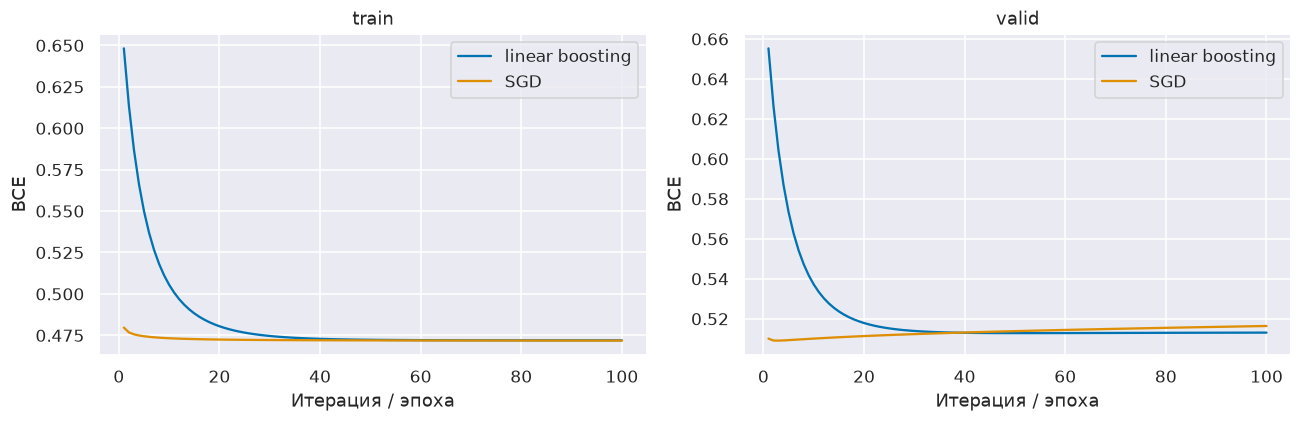

,model,seconds,train_loss,valid_loss
0,linear boosting,19.583555,0.471976,0.513052
1,SGD,16.824923,0.471805,0.516367


In [23]:
sgd = SGDClassifier(loss="log_loss", alpha=1e-5, learning_rate="invscaling",
                    eta0=.01, power_t=.5, random_state=SEED, shuffle=True)
sgd_history = {key: [] for key in ["train_loss", "valid_loss", "train_roc_auc", "valid_roc_auc"]}
start = perf_counter()
for epoch in range(100):
    sgd.partial_fit(linear_train, y_train, classes=np.array([-1, 1]))
    for name, xx, yy in [("train", linear_train, y_train), ("valid", linear_valid, y_valid)]:
        raw = sgd.decision_function(xx)
        sgd_history[name + "_loss"].append(np.logaddexp(0, -yy * raw).mean())
        sgd_history[name + "_roc_auc"].append(roc_auc_score(yy, raw))
sgd_seconds = perf_counter() - start
# Одинаковый бюджет: время обоих методов включает оценку метрик на каждой итерации.
print("SGD seconds:", sgd_seconds, "valid AUC:", sgd_history["valid_roc_auc"][-1])
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, split in zip(axes, ["train", "valid"]):
    ax.plot(np.arange(1, 101), linear_boost.history[split + "_loss"], label="linear boosting")
    ax.plot(np.arange(1, 101), sgd_history[split + "_loss"], label="SGD")
    ax.set(title=split, xlabel="Итерация / эпоха", ylabel="BCE")
    ax.legend()
plt.tight_layout(); plt.show()
linear_comparison = pd.DataFrame([
    {"model": "linear boosting", "seconds": linear_boost_seconds,
     "train_loss": linear_boost.history["train_loss"][-1], "valid_loss": linear_boost.history["valid_loss"][-1]},
    {"model": "SGD", "seconds": sgd_seconds,
     "train_loss": sgd_history["train_loss"][-1], "valid_loss": sgd_history["valid_loss"][-1]}])
display(linear_comparison)


**Наблюдение.** За 100 итераций линейный бустинг обучился за 19.58 с (valid AUC 0.8269, BCE 0.5131), SGD — за 16.82 с (AUC 0.8252, BCE 0.5164). Train BCE почти одинакова: 0.4720 и 0.4718. SGD здесь немного быстрее; по valid линейный бустинг немного лучше. Результат относится к этим шагам обучения и регуляризации.

Покажите на одном графике изменение функции потерь для бустинга и SGD классификатора. Сравните следующие детали у бустинга и линейной модели:

- время обучения
- сходимость (как быстро, как стабильно и прочее)
- графики функции потерь на трейне и на валидации

<div style="border-left: 5px solid #ff748c; padding: 10px 20px 2px; margin: 15px 0 15px 20px; max-width: 800px; background-color: rgba(255, 116, 140, 0.05);">

**Вопрос:** Какой вывод вы можете сделать?

**Ответ:** Линейный бустинг снижает BCE последовательными проекциями антиградиента на линейные
функции. SGD непосредственно оптимизирует линейный классификатор; его поведение зависит от
шага и регуляризации. Сравниваем 100 итераций/эпох на одинаково масштабированных матрицах;
они не эквивалентны по количеству операций. Численные времена и конечные потери приведены
в таблице выше. Нелинейности от суммы линейных моделей не появляется.

</div>

### 💠 2.11. Потери потерь (0.5 балла)

Если вы смотрели в датасет, то вероятно заметили, что данные в нём несбалансированы. С этим можно жить, и этому вы научитесь на мо2, но нужно ли? Ведь всегда можно шлёпнуть простой советский проверенный способ, который в бустингах применяется не слишком широко, по непонятной, честно говоря, причине.

Смотрите, какая существует штука:

$$
\text{FocalLoss}(y, z) = -\frac{1}{n}\sum_{i=1}^{n} \left(1 - \sigma(y_i z_i)\right)^{\gamma} \log\!\big(\sigma(y_i z_i)\big)
$$

Что же это за покемон?
- параметр $\gamma$ (это другой гамма, свой, не бустинговый) регулирует, как сильно я акцентирую внимание на тех объектах, которых много, и которые легко разметить. Чем он больше, тем больше игнорим лёгкие примеры
- вес $(1 - \sigma(y_i z_i))$ регулирует вклад в лосс, в зависимости от класса
- в остальном это тот же логлосс

>Если разметить объект легко, то есть сигмоида даёт результат, близкий к единице, то нам как бы максимально всё равно, какой у него вклад в лосс, множитель под гаммой будет примерно 0, интереснее же на сложных примерах обучаться. А если сложно, то вклад напротив максимальный, объект полностью участвует в расчёте лосса

Хочется увидеть в классе `Boosting`:
- `loss: str = 'BCE` — лосс, на который обучаем бустинг, по дефолту `'BCE'` - бинарная кросс-энтропия, aka логистическая функция потерь
- `focal_gamma: float = 2.0` — гиперпараметр для силы фокал лосса, чем-то похож на `class_weights`, но поинтереснее
- методы `loss_fn` и `grad_fn` для фокал лосса

<div align="center">

<table>
<tr>
<td align="center"><b><font color="#2f82d4">XGBoost</font></b></td>
<td align="center"><b><font color="#53c96c">LightGBM</font></b></td>
<td align="center"><b><font color="#c4bf0a">CatBoost</font></b></td>
</tr>
<tr>
<td align="center"><code>objective="custom"</code></td>
<td align="center"><code>objective="custom"</code></td>
<td align="center"><code>loss_function="FocalLoss"</code></td>
</tr>
</table>

</div>

Получилось? Покажите. Должно было стать чуть получше

,model,iterations,seconds,train_auc,valid_auc,valid_logloss
14,focal,70,92.50101,0.87931,0.80008,0.57653


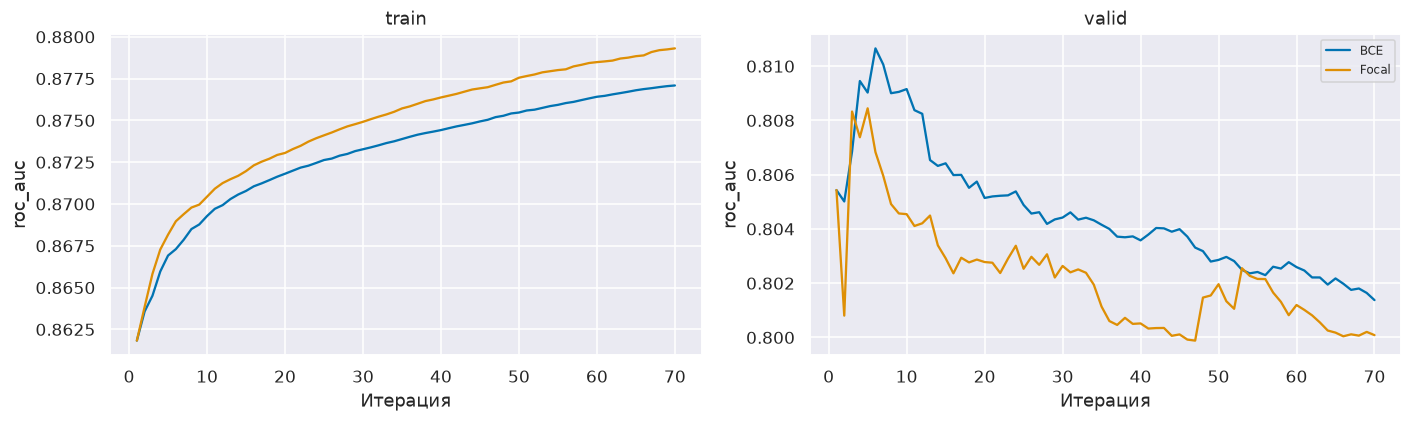

,model,iterations,seconds,train_auc,valid_auc,valid_logloss
4,categories_ordered,70,75.52379,0.87709,0.80137,0.53984
14,focal,70,92.50101,0.87931,0.80008,0.57653


In [24]:
focal_model = experiment("focal", loss="Focal", focal_gamma=2)
compare_curves({"BCE": cat_ordered, "Focal": focal_model})
# Лоссы BCE и Focal численно несопоставимы; сравниваем ещё общий BCE на valid.
display(pd.DataFrame(results).query("model in ['categories_ordered', 'focal']").round(5))


Обозначим $p=\sigma(yz)$, $q=1-p$. Производная focal loss по отступу:
$\partial L/\partial z=yq^{\gamma}(\gamma p\log p-q)$.
При $\gamma=0$ она совпадает с производной BCE; это проверено численным
дифференцированием. В данных классы почти сбалансированы, поэтому обещать улучшение
нельзя. Focal снижает вес **лёгких**, а не обязательно объектов большого класса;
без множителя alpha он сам по себе не задаёт классовые веса.


**Наблюдение.** Focal не улучшил результат: AUC 0.8001 против 0.8014, общий BCE 0.5765 против 0.5398. Меньшее численное значение самого focal loss нельзя считать улучшением BCE. Классы в этом файле почти сбалансированы.


------

## Задание 3. Около бустинга (📌 1 балл |💠 1.25 балла)

Теперь давайте проанализируем, как же правильно готовить бустинги. Нас интересует: как тюнить бустинги, какие они вообще бывают и как их интерпретировать. Посмотрим на все это по порядку

### 📌 3.1. Optuna наносит ответный удар (0.5 балла)

Если вы помните, у нас уже было знакомство с библиотекой `optuna` для подбора гиперпараметров. Вспомним, как это делается и подумаем, как это можно делать еще лучше

Подберите на валидации оптимальные значения следующих гиперпараметров для вашей реализации бустинга:
- `max_depth`
- `n_estimators`
- `learning_rate`
- любые другие, которые вы сделали в части 2

Подберите диапазон параметров самостоятельно, не забывайте фиксировать сид (нет, его не нужно перебирать). Сохраните и покажите оптимальный набор параметров. Покажите, какие из них дали наибольший прирост.

In [25]:
import optuna
from optuna.importance import get_param_importances
optuna.logging.set_verbosity(optuna.logging.INFO)

def objective(trial, model="custom_boosting"):
    boosting_params = dict(
        n_estimators=trial.suggest_int("n_estimators", 70, 245, step=35),
        learning_rate=trial.suggest_float("learning_rate", .15, .8, log=True),
        rsm=trial.suggest_float("rsm", .65, 1),
        bootstrap_type=trial.suggest_categorical("bootstrap_type", ["Bernoulli", "Bayesian"]),
        quantization_type=trial.suggest_categorical("quantization_type", [None, "uniform", "quantile"]),
        cat_features=cat_features, nbins=64, random_state=SEED, verbose=False,
        early_stopping_rounds=15, eval_metric="valid_roc_auc")
    tree_params = dict(max_depth=trial.suggest_int("max_depth", 3, 8), min_samples_leaf=30)
    conditional_params = (
        {"subsample": trial.suggest_float("subsample", .45, 1.)}
        if boosting_params["bootstrap_type"] == "Bernoulli" else
        {"bagging_temperature": trial.suggest_float("bagging_temperature", .1, 1.5)})
    candidate = Boosting(**boosting_params, **conditional_params, base_model_params=tree_params)
    candidate.fit(X_train, y_train, eval_set=(X_valid, y_valid), use_best_model=True)
    trial.set_user_attr("best_iteration", candidate.best_iteration_ + 1)
    return candidate.score(X_valid, y_valid)

study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=SEED))
# Известная разумная точка — затем воспроизводимый поиск, без использования test.
study.enqueue_trial({"n_estimators": 70, "learning_rate": .3, "max_depth": 5,
                     "rsm": 1., "bootstrap_type": "Bernoulli", "subsample": 1.,
                     "quantization_type": "uniform"})
study.optimize(objective, n_trials=12)
print("Лучшие параметры:", study.best_params)
print("Лучший valid ROC-AUC:", study.best_value)
display(study.trials_dataframe().sort_values("value", ascending=False))


[I 2026-11-10 18:19:37,525] A new study created in memory with name: no-name-736da5c5-0d56-46cd-94c0-3c91c42ef8de


[I 2026-11-10 18:20:48,023] Trial 0 finished with value: 0.8306047473807732 and parameters: {'n_estimators': 70, 'learning_rate': 0.3, 'rsm': 1.0, 'bootstrap_type': 'Bernoulli', 'quantization_type': 'uniform', 'max_depth': 5, 'subsample': 1.0}. Best is trial 0 with value: 0.8306047473807732.


[I 2026-11-10 18:21:10,391] Trial 1 finished with value: 0.8074714374133081 and parameters: {'n_estimators': 105, 'learning_rate': 0.5811422615786251, 'rsm': 0.7725883838281941, 'bootstrap_type': 'Bernoulli', 'quantization_type': None, 'max_depth': 7, 'subsample': 0.8338063113509406}. Best is trial 0 with value: 0.8306047473807732.


[I 2026-11-10 18:21:40,161] Trial 2 finished with value: 0.8318684722874494 and parameters: {'n_estimators': 210, 'learning_rate': 0.5608861258218885, 'rsm': 0.6767317121377575, 'bootstrap_type': 'Bayesian', 'quantization_type': 'uniform', 'max_depth': 4, 'bagging_temperature': 0.7368686183537835}. Best is trial 2 with value: 0.8318684722874494.


[I 2026-11-10 18:21:55,711] Trial 3 finished with value: 0.8129056662633009 and parameters: {'n_estimators': 175, 'learning_rate': 0.2449763136415902, 'rsm': 0.7469413017580633, 'bootstrap_type': 'Bernoulli', 'quantization_type': None, 'max_depth': 5, 'subsample': 0.7322721683717879}. Best is trial 2 with value: 0.8318684722874494.


[I 2026-11-10 18:22:06,007] Trial 4 finished with value: 0.8161778586508174 and parameters: {'n_estimators': 245, 'learning_rate': 0.3648088215799758, 'rsm': 0.888152655174081, 'bootstrap_type': 'Bernoulli', 'quantization_type': None, 'max_depth': 4, 'subsample': 0.5015433838239467}. Best is trial 2 with value: 0.8318684722874494.


... (5 outputs left out)

[I 2026-11-10 18:24:38,909] Trial 10 finished with value: 0.8363426617724167 and parameters: {'n_estimators': 210, 'learning_rate': 0.2781893374562971, 'rsm': 0.8410858458958894, 'bootstrap_type': 'Bayesian', 'quantization_type': 'uniform', 'max_depth': 8, 'bagging_temperature': 0.13363430832181955}. Best is trial 7 with value: 0.8373794108154492.


[I 2026-11-10 18:25:20,121] Trial 11 finished with value: 0.8373810966893984 and parameters: {'n_estimators': 105, 'learning_rate': 0.2543858450219287, 'rsm': 0.7763685746241655, 'bootstrap_type': 'Bayesian', 'quantization_type': 'uniform', 'max_depth': 8, 'bagging_temperature': 0.10617990717836014}. Best is trial 11 with value: 0.8373810966893984.


Лучшие параметры: {'n_estimators': 105, 'learning_rate': 0.2543858450219287, 'rsm': 0.7763685746241655, 'bootstrap_type': 'Bayesian', 'quantization_type': 'uniform', 'max_depth': 8, 'bagging_temperature': 0.10617990717836014}
Лучший valid ROC-AUC: 0.8373810966893984


,number,value,datetime_start,datetime_complete,duration,params_bagging_temperature,params_bootstrap_type,params_learning_rate,params_max_depth,params_n_estimators,params_quantization_type,params_rsm,params_subsample,user_attrs_best_iteration,system_attrs_fixed_params,system_attrs_tpe:relative_params:0,state
11,11,0.837381,2026-11-10 18:24:38.910670,2026-11-10 18:25:20.120942,0 days 00:00:41.210272,0.106180,Bayesian,0.254386,8,105,uniform,0.776369,NaN,17,NaN,"{""bootstrap_type"": ""Bayesian"", ""learning_rate""...",COMPLETE
7,7,0.837379,2026-11-10 18:22:34.004429,2026-11-10 18:23:22.881867,0 days 00:00:48.877438,0.493789,Bayesian,0.379919,8,70,uniform,0.694375,NaN,27,NaN,NaN,COMPLETE
10,10,0.836343,2026-11-10 18:24:01.511057,2026-11-10 18:24:38.909754,0 days 00:00:37.398697,0.133634,Bayesian,0.278189,8,210,uniform,0.841086,NaN,13,NaN,"{""bootstrap_type"": ""Bayesian"", ""learning_rate""...",COMPLETE
9,9,0.831978,2026-11-10 18:23:40.112900,2026-11-10 18:24:01.510255,0 days 00:00:21.397355,0.259521,Bayesian,0.357388,4,105,uniform,0.841631,NaN,11,NaN,NaN,COMPLETE
2,2,0.831868,2026-11-10 18:21:10.392165,2026-11-10 18:21:40.160900,0 days 00:00:29.768735,0.736869,Bayesian,0.560886,4,210,uniform,0.676732,NaN,28,NaN,NaN,COMPLETE
0,0,0.830605,2026-11-10 18:19:37.527272,2026-11-10 18:20:48.023213,0 days 00:01:10.495941,NaN,Bernoulli,0.300000,5,70,uniform,1.000000,1.000000,70,"{'n_estimators': 70, 'learning_rate': 0.3, 'ma...",NaN,COMPLETE
8,8,0.819471,2026-11-10 18:23:22.882734,2026-11-10 18:23:40.112140,0 days 00:00:17.229406,1.071930,Bayesian,0.309696,3,210,quantile,0.791637,NaN,10,NaN,NaN,COMPLETE
5,5,0.817336,2026-11-10 18:22:06.008462,2026-11-10 18:22:15.718997,0 days 00:00:09.710535,NaN,Bernoulli,0.577965,4,140,quantile,0.717728,0.488156,8,NaN,NaN,COMPLETE
4,4,0.816178,2026-11-10 18:21:55.712296,2026-11-10 18:22:06.007557,0 days 00:00:10.295261,NaN,Bernoulli,0.364809,4,245,NaN,0.888153,0.501543,6,NaN,NaN,COMPLETE
3,3,0.812906,2026-11-10 18:21:40.161991,2026-11-10 18:21:55.711379,0 days 00:00:15.549388,NaN,Bernoulli,0.244976,5,175,NaN,0.746941,0.732272,8,NaN,NaN,COMPLETE


,model,iterations,seconds,train_auc,valid_auc,valid_logloss
15,best_custom,17,41.04567,0.87018,0.83738,0.53925


quantization_type    0.808704
bootstrap_type       0.111270
max_depth            0.050887
n_estimators         0.019391
learning_rate        0.005096
rsm                  0.004651
Name: fANOVA importance, dtype: float64

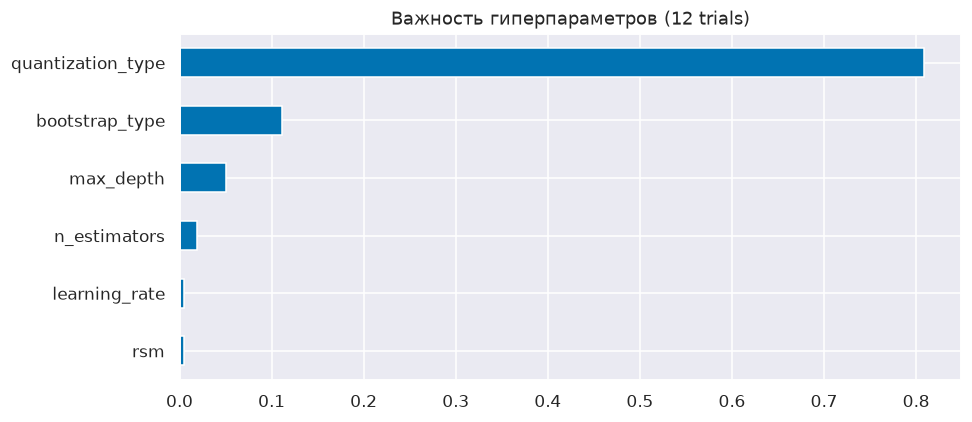

,replacement,valid_auc,winner_minus_replacement
0,max_depth=3,0.830921,0.006460
2,learning_rate=0.15,0.836942,0.000439
1,n_estimators=100,0.837381,0.000000


In [26]:
params = dict(study.best_params)
depth = params.pop("max_depth")
best_custom = Boosting(**params, cat_features=cat_features, nbins=64, random_state=SEED, verbose=False,
                       base_model_params={"max_depth": depth, "min_samples_leaf": 30},
                       early_stopping_rounds=15, eval_metric="valid_roc_auc")
start = perf_counter()
best_custom.fit(X_train, y_train, eval_set=(X_valid, y_valid), use_best_model=True)
register("best_custom", best_custom, X_valid, perf_counter() - start)
assert best_custom.score(X_valid, y_valid) >= .8
importance_params = get_param_importances(study, evaluator=optuna.importance.FanovaImportanceEvaluator(seed=SEED))
display(pd.Series(importance_params, name="fANOVA importance").sort_values(ascending=False))
pd.Series(importance_params).sort_values().plot.barh(title="Важность гиперпараметров (12 trials)")
plt.tight_layout(); plt.show()
# Однофакторные замены относительно победителя: это оценка вклада, не причинный вывод.
ablation = []
for parameter, default in [("max_depth", 3), ("n_estimators", 100), ("learning_rate", .15)]:
    altered = {**study.best_params, parameter: default}
    altered_depth = altered.pop("max_depth")
    candidate = Boosting(**altered, cat_features=cat_features, nbins=64, random_state=SEED, verbose=False,
                         base_model_params={"max_depth": altered_depth, "min_samples_leaf": 30},
                         early_stopping_rounds=15, eval_metric="valid_roc_auc")
    candidate.fit(X_train, y_train, eval_set=(X_valid, y_valid), use_best_model=True)
    auc = candidate.score(X_valid, y_valid)
    ablation.append({"replacement": f"{parameter}={default}", "valid_auc": auc,
                     "winner_minus_replacement": study.best_value - auc})
display(pd.DataFrame(ablation).sort_values("winner_minus_replacement", ascending=False))
(DATA_DIR / "best_params.json").write_text(json.dumps({"custom": study.best_params}, indent=2))
study.trials_dataframe().to_csv(DATA_DIR / "optuna_custom_trials.csv", index=False)


fANOVA показывает долю вариации качества, объяснённую параметром в этом поиске,
а не гарантированный прирост ROC-AUC. Условные параметры не входят в общую
оценку fANOVA; их значения сохранены в таблице trials. На 12 попытках важности
приблизительны. Таблица однофакторных замен показывает изменение valid AUC
при возврате отдельных параметров к простым значениям с остальными параметрами победителя.
Оптимизируется только valid; test далее используется для итоговой оценки.


**Наблюдение.** Лучший valid ROC-AUC после 12 trials — **0.8374**, выше требуемых 0.8. Победил `quantization_type=uniform`, глубина 8, learning rate 0.254; фактически сохранено 17 деревьев. Номинальный максимум числа деревьев и число сохранённых деревьев различаются из-за early stopping. Среди однофакторных замен наибольшая потеря от уменьшения глубины с 8 до 3: около 0.00646 AUC; замена шага на 0.15 даёт потерю около 0.00044, а лимит 100 вместо 105 ничего не меняет из-за остановки на 17 деревьях. Наибольшая оценка fANOVA у `quantization_type` (0.809); таблица однофакторных замен выше отдельно показывает изменение AUC.


Выбейте ROC-AUC хотя бы 0.8, и можете двигаться дальше

### 📌 3.2. Готовые реализации (0.5 балла)

Библиотек для бустингов существует много, но активно используются лишь три. Вам предстоит попробовать их в деле, посмотреть на их уникальные фишки и понять, что вам нравится больше всего

Возьмите любую из популярных библиотек: <font color='#2f82d4'>**XGBoost**</font>, <font color='#53c96c'>**LightGBM**</font> или <font color='#c4bf0a'>**CatBoost**</font>.
Ваша задача — взять одну из них, подобрать те же оптимальные параметры, что и выше, а также вставить [прунер](https://optuna.readthedocs.io/en/stable/reference/pruners.html).

Идея прунера — не обучать бустинг до конца, если по истории валидации видно, что другие бустинги на этом этапе статистически лучше, для этого мы и делали `partial_fit`, но в готовые реализации его можно вставить при помощи CallBack, для этого придётся немножко погуглить. Это во-первых, заметно ускоряет процесс перебора гиперпарамтеров, во-вторых неявно регуляризует модельку

Цель — увидеть в логах оптуны `Trial.PRUNED`, это знак того, что прунер работает. Если вы этого не видите, вероятно, вы вставили его неправильно.

In [27]:
import xgboost as xgb

# Та же предобработка, включая ordered target statistics на train.
library_encoder = TargetEncoder(cat_features)
lib_train = library_encoder.fit_transform(X_train, y_train > 0)
lib_valid = library_encoder.transform(X_valid)
y_train01, y_valid01, y_test01 = (a > 0 for a in [y_train, y_valid, y_test])

class OptunaPruningCallback(xgb.callback.TrainingCallback):
    def __init__(self, trial):
        self.trial = trial
    def after_iteration(self, model, epoch, evals_log):
        self.trial.report(evals_log["validation_0"]["auc"][-1], step=epoch)
        if self.trial.should_prune():
            raise optuna.TrialPruned(f"iteration={epoch + 1}")
        return False

def xgb_objective(trial):
    params = dict(max_depth=trial.suggest_int("max_depth", 3, 8),
                  n_estimators=trial.suggest_int("n_estimators", 70, 245, step=35),
                  learning_rate=trial.suggest_float("learning_rate", .15, .8, log=True),
                  subsample=trial.suggest_float("subsample", .45, 1.),
                  colsample_bytree=trial.suggest_float("rsm", .65, 1))
    candidate = xgb.XGBClassifier(**params, objective="binary:logistic", tree_method="hist",
        n_jobs=2, random_state=SEED, eval_metric="auc", early_stopping_rounds=15,
        callbacks=[OptunaPruningCallback(trial)])
    candidate.fit(lib_train, y_train01, eval_set=[(lib_valid, y_valid01)], verbose=False)
    trial.set_user_attr("best_iteration", candidate.best_iteration + 1)
    return roc_auc_score(y_valid01, candidate.predict_proba(lib_valid)[:, 1])

xgb_study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=SEED),
    pruner=optuna.pruners.MedianPruner(n_startup_trials=2, n_warmup_steps=10, interval_steps=5))
xgb_study.optimize(xgb_objective, n_trials=15)
print("Состояния trials:", xgb_study.trials_dataframe().state.value_counts().to_dict())
assert any(t.state == optuna.trial.TrialState.PRUNED for t in xgb_study.trials)
xgb_params = dict(xgb_study.best_params)
xgb_params["colsample_bytree"] = xgb_params.pop("rsm")
best_xgb = xgb.XGBClassifier(**xgb_params, tree_method="hist", objective="binary:logistic",
                           random_state=SEED, n_jobs=2, eval_metric="auc", early_stopping_rounds=15)
start = perf_counter()
best_xgb.fit(lib_train, y_train01, eval_set=[(lib_valid, y_valid01)], verbose=False)
xgb_seconds = perf_counter() - start
print("Лучшие параметры XGBoost:", xgb_study.best_params)
print("XGBoost valid AUC:", roc_auc_score(y_valid01, best_xgb.predict_proba(lib_valid)[:, 1]))
xgb_study.trials_dataframe().to_csv(DATA_DIR / "optuna_xgboost_trials.csv", index=False)


[I 2026-11-10 18:27:39,834] A new study created in memory with name: no-name-aef78d65-94b7-45d1-af54-f9ef5bbae5f6


[I 2026-11-10 18:27:40,372] Trial 0 finished with value: 0.811735942102535 and parameters: {'max_depth': 4, 'n_estimators': 210, 'learning_rate': 0.26960280064120096, 'subsample': 0.884175091036991, 'rsm': 0.8464721415197004}. Best is trial 0 with value: 0.811735942102535.


[I 2026-11-10 18:27:41,553] Trial 1 finished with value: 0.8178398242183295 and parameters: {'max_depth': 4, 'n_estimators': 70, 'learning_rate': 0.16542156865179794, 'subsample': 0.8203108094234144, 'rsm': 0.8942403799505985}. Best is trial 1 with value: 0.8178398242183295.


[I 2026-11-10 18:27:41,942] Trial 2 pruned. iteration=11


[I 2026-11-10 18:27:42,407] Trial 3 finished with value: 0.8140648297510988 and parameters: {'max_depth': 4, 'n_estimators': 140, 'learning_rate': 0.20311422754245595, 'subsample': 0.6279274209950054, 'rsm': 0.8092171545884459}. Best is trial 1 with value: 0.8178398242183295.


[I 2026-11-10 18:27:42,887] Trial 4 finished with value: 0.8062046117396993 and parameters: {'max_depth': 6, 'n_estimators': 105, 'learning_rate': 0.23847993202436, 'subsample': 0.8229841895862224, 'rsm': 0.7317105452119782}. Best is trial 1 with value: 0.8178398242183295.


... (8 outputs left out)

[I 2026-11-10 18:27:46,756] Trial 13 finished with value: 0.8160938731683477 and parameters: {'max_depth': 3, 'n_estimators': 105, 'learning_rate': 0.15390915378147954, 'subsample': 0.8947550315223768, 'rsm': 0.6931096313029421}. Best is trial 9 with value: 0.8190253797352811.


[I 2026-11-10 18:27:47,150] Trial 14 finished with value: 0.8185008336739763 and parameters: {'max_depth': 3, 'n_estimators': 70, 'learning_rate': 0.2127333961108461, 'subsample': 0.7256600191542295, 'rsm': 0.7262446302404163}. Best is trial 9 with value: 0.8190253797352811.


Состояния trials: {'COMPLETE': 10, 'PRUNED': 5}


Лучшие параметры XGBoost: {'max_depth': 3, 'n_estimators': 70, 'learning_rate': 0.19360931559311717, 'subsample': 0.5914006101004088, 'rsm': 0.6742808186940972}
XGBoost valid AUC: 0.8190253797352811


**Наблюдение.** Из 15 trials прунер остановил 5; состояния `PRUNED` присутствуют в сохранённой таблице и логах. Это реальная остановка по промежуточному validation AUC, а не пометка после полного обучения. Лучший XGBoost после переобучения на train дал valid AUC 0.8190.

<div style="border-left: 5px solid #ff748c; padding: 10px 20px 2px; margin: 15px 0 15px 20px; max-width: 800px; background-color: rgba(255, 116, 140, 0.05);">

**Вопрос:** Какая архитектура вам нравится больше всего и почему?

**Ответ:** Для этой задачи мне удобнее CatBoost: в исходных данных несколько категориальных
признаков, и их обработка встроена в модель. Это избавляет от самостоятельного хранения
счётчиков и контроля утечки. XGBoost удобен прозрачными callback и управлением L1/L2;
LightGBM привлекателен скоростью гистограмм и гибкостью, включая режим RF. Предпочтение
архитектуры не означает, что она всегда выигрывает по метрике; здесь это проверяется на valid.

</div>

### 💠 3.3. <font color='#2f82d4'>**XGBoost**</font> и велосипеды (0.25 баллов)

<font color='#2f82d4'>**XGBoost**</font> известен тем, что в нем впервые повилась регуляризация. Ручками ее написать сложно, и вы даже могли попробовать пунктом ранее, но зачем? Она уже написана, вообще-то. Вместо того, чтобы заниматься ерундой, можем попробовать импортировать и посмотреть, насколько она полезна в лучшем своём представлении.

Добавьте оба вида регуляризации, что там есть, как параметры в оптуну, и прогоните процесс оптимизации только на них.

<div align="center">

<table>
<tr>
<td align="center"><b><font color="#2f82d4">XGBoost</font></b></td>
<td align="center"><b><font color="#53c96c">LightGBM</font></b></td>
<td align="center"><b><font color="#c4bf0a">CatBoost</font></b></td>
</tr>
<tr>
<td align="center"><code>alpha</code>, <code>lambda</code></td>
<td align="center"><code>lambda_l1</code>, <code>lambda_l2</code></td>
<td align="center"><code>-</code>, <code>l2_leaf_reg</code></td>
</tr>
</table>

</div>

In [28]:
# Меняем только L1/L2, архитектура и бюджет фиксированы.
def regularization_objective(trial):
    params = {**xgb_params, "reg_alpha": trial.suggest_float("reg_alpha", 1e-5, 30, log=True),
              "reg_lambda": trial.suggest_float("reg_lambda", 1e-3, 100, log=True)}
    candidate = xgb.XGBClassifier(**params, random_state=SEED, n_jobs=2,
                                  tree_method="hist", eval_metric="auc", early_stopping_rounds=15)
    candidate.fit(lib_train, y_train01, eval_set=[(lib_valid, y_valid01)], verbose=False)
    return roc_auc_score(y_valid01, candidate.predict_proba(lib_valid)[:, 1])
reg_study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=SEED))
reg_study.optimize(regularization_objective, n_trials=10)
unregularized_xgb = xgb.XGBClassifier(**xgb_params, reg_alpha=0, reg_lambda=0, random_state=SEED,
    n_jobs=2, tree_method="hist", eval_metric="auc", early_stopping_rounds=15)
unregularized_xgb.fit(lib_train, y_train01, eval_set=[(lib_valid, y_valid01)], verbose=False)
regularized_xgb = xgb.XGBClassifier(**xgb_params, **reg_study.best_params, random_state=SEED,
    n_jobs=2, tree_method="hist", eval_metric="auc", early_stopping_rounds=15)
regularized_xgb.fit(lib_train, y_train01, eval_set=[(lib_valid, y_valid01)], verbose=False)
reg_comparison = pd.DataFrame([
    {"regularization": "none", "valid_auc": roc_auc_score(y_valid01, unregularized_xgb.predict_proba(lib_valid)[:, 1])},
    {"regularization": "default", "valid_auc": roc_auc_score(y_valid01, best_xgb.predict_proba(lib_valid)[:, 1])},
    {"regularization": "tuned", "valid_auc": reg_study.best_value}])
display(reg_comparison)
print("L1/L2:", reg_study.best_params)


[I 2026-11-10 18:27:47,584] A new study created in memory with name: no-name-4bf62c71-d4c9-4840-aea3-a268ea7de21a


[I 2026-11-10 18:27:48,042] Trial 0 finished with value: 0.8190276082606814 and parameters: {'reg_alpha': 0.000829548422445612, 'reg_lambda': 11.100398712060146}. Best is trial 0 with value: 0.8190276082606814.


[I 2026-11-10 18:27:48,492] Trial 1 finished with value: 0.81902860668419 and parameters: {'reg_alpha': 0.0018562141356811928, 'reg_lambda': 8.852099403875222}. Best is trial 1 with value: 0.81902860668419.


[I 2026-11-10 18:27:48,948] Trial 2 finished with value: 0.8190253797352811 and parameters: {'reg_alpha': 0.04324395256373508, 'reg_lambda': 0.018532959261934094}. Best is trial 1 with value: 0.81902860668419.


[I 2026-11-10 18:27:49,356] Trial 3 finished with value: 0.8190253797352811 and parameters: {'reg_alpha': 4.785742197924934e-05, 'reg_lambda': 0.0019602147192334116}. Best is trial 1 with value: 0.81902860668419.


[I 2026-11-10 18:27:49,750] Trial 4 finished with value: 0.8190254280016109 and parameters: {'reg_alpha': 0.2296129562503115, 'reg_lambda': 3.084240850138282}. Best is trial 1 with value: 0.81902860668419.


... (3 outputs left out)

[I 2026-11-10 18:27:51,336] Trial 8 finished with value: 0.8190253797352811 and parameters: {'reg_alpha': 0.011096584207423085, 'reg_lambda': 0.008043194828979193}. Best is trial 1 with value: 0.81902860668419.


[I 2026-11-10 18:27:51,731] Trial 9 finished with value: 0.8190253797352811 and parameters: {'reg_alpha': 0.0012455960919130979, 'reg_lambda': 0.1881615057552575}. Best is trial 1 with value: 0.81902860668419.


,regularization,valid_auc
0,none,0.819025
1,default,0.819025
2,tuned,0.819029


L1/L2: {'reg_alpha': 0.0018562141356811928, 'reg_lambda': 8.852099403875222}


**Наблюдение.** Valid AUC без штрафов — 0.819025, со стандартными — 0.819025, с подобранными — 0.819029. Прирост подбора относительно нулевых штрафов: +0.000004. В данной конфигурации эффект практически нулевой; различие такого масштаба нельзя считать убедительным улучшением качества.

<div style="border-left: 5px solid #ff748c; padding: 10px 20px 2px; margin: 15px 0 15px 20px; max-width: 800px; background-color: rgba(255, 116, 140, 0.05);">

**Вопрос:** Насколько регуляризация вообще эффективна?

**Ответ:** L1 зануляет слабые веса листьев, L2 уменьшает их величину. При глубоких деревьях это
может уменьшить переобучение, но сильный штраф приводит к недообучению. В таблице сравниваются
нулевые, стандартные и подобранные штрафы при одной архитектуре. Выбор по valid может дать
оптимистичную оценку улучшения, поэтому окончательная проверка вынесена на test.

</div>

### 💠 3.4. <font color='#53c96c'>**LightGBM**</font>, лес vs бустинг (0.25 балла)

<font color='#53c96c'>**LightGBM**</font> велик по многим причинам. В нём самое большое количество гиперпараметров из всех библиотек. А ещё он содержит в себе реализацию своего злейшего врага — случайный лес, это очень по-философски.

Посмотрите, какие есть параметры у него, обучите так сильно, как только сможете (не забудьте про свойства случайного леса к переобучению, про категориальные энкодеры и прочее).

<div align="center">

<table>
<tr>
<td align="center"><b><font color="#2f82d4">XGBoost</font></b></td>
<td align="center"><b><font color="#53c96c">LightGBM</font></b></td>
<td align="center"><b><font color="#c4bf0a">CatBoost</font></b></td>
</tr>
<tr>
<td align="center"><code>num_parallel_tree</code></td>
<td align="center"><code>boosting_type="rf"</code></td>
<td align="center"><code>-</code></td>
</tr>
</table>

</div>

In [29]:
import lightgbm as lgb

rf_search = []
rf_models = []
for leaves, fraction in [(15, .7), (31, .7), (63, .8), (127, .8)]:
    candidate = lgb.LGBMClassifier(boosting_type="rf", n_estimators=250, num_leaves=leaves,
        min_child_samples=50, subsample=.7, subsample_freq=1, colsample_bytree=fraction,
        random_state=SEED, n_jobs=2, verbosity=-1)
    candidate.fit(lib_train, y_train01)
    rf_models.append(candidate)
    rf_search.append({"num_leaves": leaves, "colsample_bytree": fraction,
                      "train_auc": roc_auc_score(y_train01, candidate.predict_proba(lib_train)[:, 1]),
                      "valid_auc": roc_auc_score(y_valid01, candidate.predict_proba(lib_valid)[:, 1])})
rf_table = pd.DataFrame(rf_search)
best_rf = rf_models[int(rf_table.valid_auc.argmax())]
display(rf_table)
print("Для RF обязательны subsample_freq > 0 и subsample/feature_fraction < 1.")


,num_leaves,colsample_bytree,train_auc,valid_auc
0,15,0.7,0.864745,0.815093
1,31,0.7,0.870500,0.803865
2,63,0.8,0.874154,0.800263
3,127,0.8,0.877971,0.796446


Для RF обязательны subsample_freq > 0 и subsample/feature_fraction < 1.


**Наблюдение.** Лучший RF дал valid AUC 0.8151, XGBoost — 0.8190; по valid выиграл бустинг XGBoost. Это сравнение конкретных конфигураций и бюджетов: диапазон подбора леса меньше, чем у бустинга.

<div style="border-left: 5px solid #ff748c; padding: 10px 20px 2px; margin: 15px 0 15px 20px; max-width: 800px; background-color: rgba(255, 116, 140, 0.05);">

**Вопрос:** Кто победит: бустинг или лес? и почему?

**Ответ:** У бустинга последовательное обучение уменьшает смещение, у леса усреднение независимых
деревьев уменьшает разброс. На этой табличной задаче результат определяется взаимодействиями
и временным сдвигом; победитель по valid указан в сравнении моделей. Даже много деревьев
леса не устраняет его смещение. Превосходство одной модели здесь нельзя переносить на все задачи.

</div>

### 💠 3.5. Еще пара красивых слов про <font color='#c4bf0a'>**CatBoost**</font> (0.25 балла)

<font color='#c4bf0a'>**CatBoost**</font> славится ещё и кучей разных подходов к обучению деревьев, в частности он умеет мёрджить несколько моделей в одно. Это не стекинг, и даже не беггинг, а совершенно другой уровень. Поскольку бустинги это уже некоторая сумма деревьев, ничего не мешает брать и складывать уже сами бустинги между собой.

 Попробуйте разбить выборку на фолды и обучить по катбусту на каждом из них, а затем их склеить. Тюнить их не надо, он и так неплох, в этом его сила и мудрость.

<div align="center">

<table>
<tr>
<td align="center"><b><font color="#2f82d4">XGBoost</font></b></td>
<td align="center"><b><font color="#53c96c">LightGBM</font></b></td>
<td align="center"><b><font color="#c4bf0a">CatBoost</font></b></td>
</tr>
<tr>
<td align="center"><code>-</code></td>
<td align="center"><code>-</code></td>
<td align="center"><code>sum_models</code>, <code>to_classifier</code></td>
</tr>
</table>

</div>

Оцените, насколько это круто по 10-балльной

In [30]:
from catboost import CatBoostClassifier, sum_models, to_classifier
from sklearn.model_selection import StratifiedKFold

cat_train_frame = X.loc[train_mask].iloc[train_permutation].reset_index(drop=True).copy()
cat_valid_frame = X.loc[valid_mask].copy()
for c in cat_names:
    cat_train_frame[c] = cat_train_frame[c].astype(str)
    cat_valid_frame[c] = cat_valid_frame[c].astype(str)
cat_params = dict(iterations=220, depth=6, learning_rate=.12, loss_function="Logloss",
                  random_seed=SEED, thread_count=2, verbose=False, allow_writing_files=False)
cat_full = CatBoostClassifier(**cat_params)
cat_full.fit(cat_train_frame, y_train01, cat_features=cat_names)
fold_models, fold_scores = [], []
for train_idx, hold_idx in StratifiedKFold(3, shuffle=True, random_state=SEED).split(cat_train_frame, y_train01):
    candidate = CatBoostClassifier(**cat_params)
    candidate.fit(cat_train_frame.iloc[train_idx], y_train01[train_idx], cat_features=cat_names)
    fold_models.append(candidate)
    fold_scores.append(roc_auc_score(y_valid01, candidate.predict_proba(cat_valid_frame)[:, 1]))
# KeepAllTables сохраняет исходные CTR, чтобы сумма в точности воспроизводила сумму logits.
cat_merged = to_classifier(sum_models(fold_models, weights=[1/3]*3, ctr_merge_policy="KeepAllTables"))
merged_raw = cat_merged.predict(cat_valid_frame, prediction_type="RawFormulaVal")
mean_raw = np.mean([m.predict(cat_valid_frame, prediction_type="RawFormulaVal") for m in fold_models], axis=0)
assert np.allclose(merged_raw, mean_raw, atol=1e-9)
cat_comparison = pd.DataFrame({"model": ["full train", "fold 1", "fold 2", "fold 3", "merged"],
    "valid_auc": [roc_auc_score(y_valid01, cat_full.predict_proba(cat_valid_frame)[:, 1]),
                  *fold_scores, roc_auc_score(y_valid01, cat_merged.predict_proba(cat_valid_frame)[:, 1])]})
display(cat_comparison)
print("Практическая оценка приёма: 8/10 — удобное слияние, но тройные обучение и размер.")


,model,valid_auc
0,full train,0.818584
1,fold 1,0.810512
2,fold 2,0.816304
3,fold 3,0.810514
4,merged,0.820326


Практическая оценка приёма: 8/10 — удобное слияние, но тройные обучение и размер.


**Наблюдение.** CatBoost на полном train: valid AUC 0.8186; объединение трёх моделей: 0.8203. Проверка равенства объединённых logits среднему исходных прошла. Усреднение logits не равно усреднению вероятностей; `KeepAllTables` сохраняет CTR отдельных моделей.

### 💠 3.6. Бустинг и вероятности (0.5 балла)

С качеством мы более-менее разобрались, но таки что насчет вероятностей? Постройте калибровочную кривую для вашей лучшей модели бустинга. Насколько хорошо бустинг оценивает вероятности?

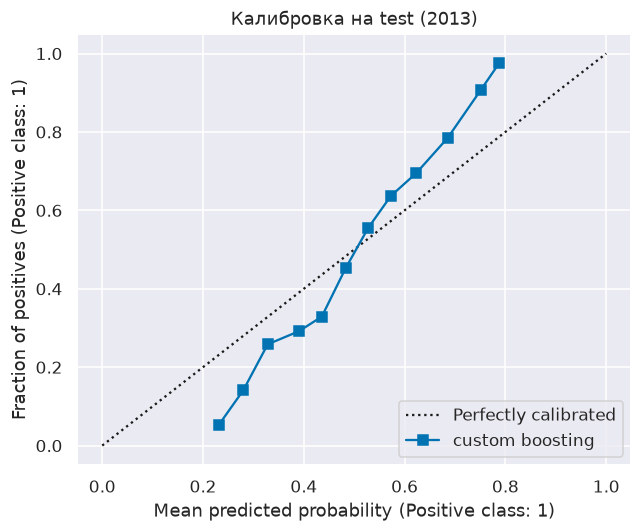

In [31]:
from sklearn.calibration import CalibrationDisplay, CalibratedClassifierCV
from sklearn.frozen import FrozenEstimator

# Выбор лучшей собственной модели сделан на valid; калибровочные графики — на test.
best_custom_test_proba = best_custom.predict_proba(X_test)[:, 1]
fig, ax = plt.subplots(figsize=(6, 5))
CalibrationDisplay.from_predictions(y_test01, best_custom_test_proba, n_bins=12,
                                    strategy="quantile", name="custom boosting", ax=ax)
ax.set_title("Калибровка на test (2013)")
plt.tight_layout(); plt.show()


**Наблюдение.** У лучшего собственного бустинга test AUC 0.8318, LogLoss 0.5433, BrierScore 0.1800. По графику модель недостаточно уверена: в нижних бинах реальная доля положительных меньше предсказанной, а в верхних — больше. Вероятности сжаты к середине; ROC-AUC этого не отражает.


Постройте также калибровочную кривую для логистической регрессии, сравните их между собой. Проанализируйте полученные результаты.

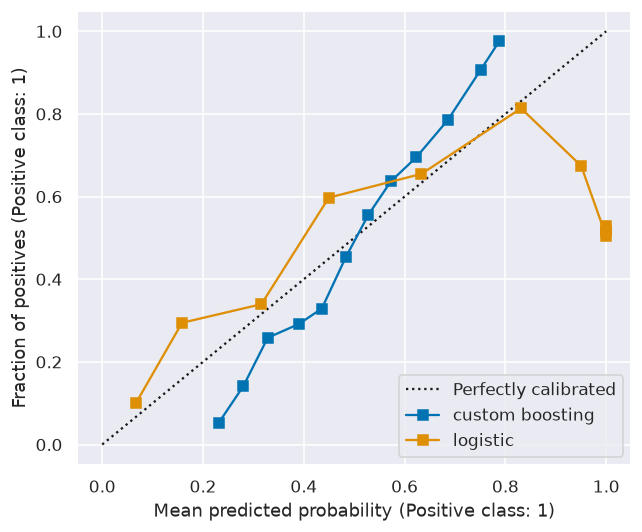

In [32]:
# Логистическая регрессия на тех же признаках и статистиках, обучение только на train.
logistic = make_pipeline(StandardScaler(), LogisticRegression(C=1, max_iter=1000, random_state=SEED))
logistic.fit(lib_train, y_train01)
lib_test = library_encoder.transform(X_test)
logistic_test_proba = logistic.predict_proba(lib_test)[:, 1]
fig, ax = plt.subplots(figsize=(6, 5))
for name, proba in [("custom boosting", best_custom_test_proba), ("logistic", logistic_test_proba)]:
    CalibrationDisplay.from_predictions(y_test01, proba, n_bins=12, strategy="quantile", name=name, ax=ax)
plt.tight_layout(); plt.show()


**Наблюдение.** Логистическая регрессия дала test AUC 0.5996, LogLoss 5.3109 и BrierScore 0.3238. Верхние бины логистической модели лежат заметно ниже диагонали: она переоценивает вероятность положительного класса в этом диапазоне. Калибровка может нарушаться при временном сдвиге; сама логистическая функция не гарантирует её качества.

Конечно же, бустинг великолепен, как он есть, но можно сделать его еще лучше, если его откалибровать

1. Посмотрите на то, как это делать из библиотеки `sklearn`. Обратите внимание, передаете вы в него обученную модель или нет, а также на чем вы калибруетесь. Иначе есть риск что-то поломать
2. Откалибруйте вашу реализацию бустинга. Для этого за вас к нему был замешан `ClassifierMixin`
3. Покажите, как изменилась мера откалиброванности, для этого есть
$$\text{LogLoss} = -\frac{1}{N}\sum_{i} \sum_{k \in {0. 1}}\log p_k[y_i = k]; \qquad \text{BrierScore} = \frac{1}{N}\sum_{i} (p_i - y_i)^2;$$
4. Нарисуйте новую калибровочную кривую

,model,ROC_AUC,LogLoss,BrierScore
0,best custom (tuned),0.831821,0.543278,0.180006
1,fixed custom before calibration,0.797404,0.543918,0.185215
2,fixed custom calibrated,0.797404,0.543854,0.185142
3,logistic,0.599556,5.310947,0.323849


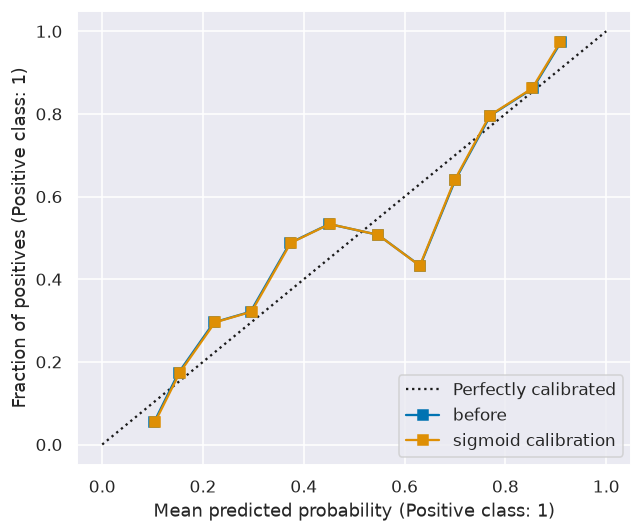

,model,test_auc,test_logloss,test_brier
0,custom,0.831821,0.543278,0.180006
2,XGBoost regularized,0.813089,0.566783,0.190306
1,XGBoost,0.813056,0.566595,0.190229
5,CatBoost merged,0.811362,0.525526,0.177370
3,LightGBM RF,0.808877,0.540435,0.181067
7,custom calibrated,0.797404,0.543854,0.185142
4,CatBoost full,0.796210,0.542522,0.184757
6,logistic,0.599556,5.310947,0.323849


In [33]:
# Valid разделяем: первая половина для выбора уже найденной конфигурации,
# вторая — для калибровки. Метки calibration не определяют ни число деревьев, ни пороги.
# Исходный поиск использовал весь valid, поэтому для строгой независимости здесь
# берём фиксированную заранее конфигурацию COMMON и фиксированное число деревьев.
selection_idx, calibration_idx = train_test_split(np.arange(len(X_valid)), test_size=.5,
                                                  stratify=y_valid, random_state=SEED)
calibration_base = Boosting(**COMMON, cat_features=cat_features)
calibration_base.fit(X_train, y_train, eval_set=(X_valid[selection_idx], y_valid[selection_idx]), use_best_model=True)
calibrated = CalibratedClassifierCV(FrozenEstimator(calibration_base), method="sigmoid")
calibrated.fit(X_valid[calibration_idx], y_valid[calibration_idx])
base_test_proba = calibration_base.predict_proba(X_test)[:, 1]
calibrated_test_proba = calibrated.predict_proba(X_test)[:, 1]
calibration_table = pd.DataFrame([
    {"model": name, "ROC_AUC": roc_auc_score(y_test01, proba),
     "LogLoss": log_loss(y_test01, proba), "BrierScore": brier_score_loss(y_test01, proba)}
    for name, proba in [("best custom (tuned)", best_custom_test_proba),
                        ("fixed custom before calibration", base_test_proba),
                        ("fixed custom calibrated", calibrated_test_proba),
                        ("logistic", logistic_test_proba)]])
display(calibration_table)
fig, ax = plt.subplots(figsize=(6, 5))
for name, proba in [("before", base_test_proba), ("sigmoid calibration", calibrated_test_proba)]:
    CalibrationDisplay.from_predictions(y_test01, proba, n_bins=12, strategy="quantile", name=name, ax=ax)
plt.tight_layout(); plt.show()

# Итоговые тестовые метрики после завершения подбора.
cat_test_frame = X.loc[test_mask].copy()
for c in cat_names:
    cat_test_frame[c] = cat_test_frame[c].astype(str)
final_predictions = {
    "custom": best_custom_test_proba,
    "XGBoost": best_xgb.predict_proba(lib_test)[:, 1],
    "XGBoost regularized": regularized_xgb.predict_proba(lib_test)[:, 1],
    "LightGBM RF": best_rf.predict_proba(lib_test)[:, 1],
    "CatBoost full": cat_full.predict_proba(cat_test_frame)[:, 1],
    "CatBoost merged": cat_merged.predict_proba(cat_test_frame)[:, 1],
    "logistic": logistic_test_proba,
    "custom calibrated": calibrated_test_proba}
final_metrics = pd.DataFrame([
    {"model": name, "test_auc": roc_auc_score(y_test01, proba),
     "test_logloss": log_loss(y_test01, proba), "test_brier": brier_score_loss(y_test01, proba)}
    for name, proba in final_predictions.items()]).sort_values("test_auc", ascending=False)
display(final_metrics)
final_metrics.to_csv(DATA_DIR / "final_metrics.csv", index=False)
pd.DataFrame(results).to_csv(DATA_DIR / "experiments.csv", index=False)
all_best_params = {"seed": SEED, "custom": study.best_params, "xgboost": xgb_study.best_params,
                   "xgboost_regularization": reg_study.best_params, "versions": versions,
                   "custom_fixed": {"nbins": 64, "min_samples_leaf": 30, "ordered": True,
                                    "cat_features": cat_names, "best_iteration": best_custom.n_estimators_}}
_ = (DATA_DIR / "best_params.json").write_text(json.dumps(all_best_params, indent=2))


**Наблюдение.** На test до/после калибровки LogLoss равен 0.543918/0.543854, BrierScore — 0.185215/0.185142. ROC-AUC 0.7974/0.7974. Сравниваются вероятности одного и того же ансамбля; подбор лучшей модели и обучение калибратора разделены. Улучшение вероятностей очень мало; рассчитывать на заметный эффект калибровки в этом эксперименте нельзя.

<div style="border-left: 5px solid #ff748c; padding: 10px 20px 2px; margin: 15px 0 15px 20px; max-width: 800px; background-color: rgba(255, 116, 140, 0.05);">

**Вопрос:** Как вы можете прокомментировать то, что получилось?

**Ответ:** Высокий ROC-AUC ещё не означает точные вероятности. Для сравнения калибровки важны
близость кривой к диагонали, LogLoss и BrierScore; меньшие значения двух последних лучше.
Sigmoid-калибровка учится на отдельной части valid поверх FrozenEstimator, поэтому исходный
ансамбль не переобучается. В паре «до/после» используется одна и та же базовая модель;
для её выбора не использованы метки calibration. Test не участвует в обучении калибратора.
Монотонное преобразование обычно сохраняет ROC-AUC, но меняет качество вероятностей.

</div>

## Музыкальный бонус. (0.5 балла) 🎶

В честь окончания весны исполните песню, которая больше всего ассоциируется у вас с МО-1, будь то Ольга Бузова, Валентин Стрыкало, Игорь Вихорьков, Глеб Смирнов или любой другой заслуженный артист. Одни, в бойз или гёрлз-бенде, вокально или инструментально (например, вашему вниманию представляется раритетнейшая [аранжировка](https://disk.360.yandex.ru/i/mY8spsw_d6abLA) на незабвенную классику за авторством Михаила Шелега), проявите фантазию. 

к сожалению, наступает зима